# FIFA World Cup 2026 — Linear Regression (Assessment 3, Objective 2)

**Author:** Divya Malla (S406481) · Sydney Group 25

## Introduction
All 104 matches of the FIFA World Cup 2026 have been played. This notebook asks two related questions:

* **Question 2.1:** using only information available **before kick-off**, how well can a multiple linear regression predict the **goal difference** of a match?
* **Question 2.2:** using the same kind of information, how well can it predict the **number of goals one team scores** in a match?

| Task | Response | Rows | Explanatory variables |
|---|---|---|---|
| **LR 2.1** | goal difference of the match (team 1 − team 2) | 104 (one per match) | exactly 8 |
| **LR 2.2** | goals scored by a team in the match | 208 (one per team per match) | exactly 8 |

**How the two tasks are linked:** a match's goal difference (2.1) is exactly team 1's goals minus team 2's goals (2.2). Model 2.1 asks *who wins and by how much*; model 2.2 breaks that down into *how many goals each side scores*.

**Our approach.** Instead of using ready-made match statistics, we **build every explanatory variable ourselves** from raw match results:
1. `data_raw/fbref_wc2026_scores_fixtures.html`: FBref's *2026 World Cup Scores & Fixtures* table, with all 104 matches.
2. `data_raw/results.csv`: every men's international match since 1872, about 49,900 matches, used to build each team's pre-match history.

From the history we calculate our own **Elo ratings**, recent **form**, **attack/defence** records, **World Cup experience**, **rest days**, **host advantage** and **tournament form**. Every value comes only from matches played **before** the match being predicted, so nothing is known that would not have been known at kick-off.

**Contents.**
1. Set-up
2. Data loading and integrity checks
3. Feature engineering, leakage test and a first look at the story
4. LR 2.1: variables, EDA, selection, OLS, evaluation, step-by-step optimisation, competing algorithms and recommendation
5. LR 2.2: the same steps
6. Assumption checks
7. Summary of both tasks
8. Conclusion

## 1 · Set-up
Imports the libraries, fixes the random seed so the numbers can be reproduced, and sets a simple chart style.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats
from sklearn.model_selection import train_test_split, RepeatedKFold, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

# chart style: recessive grid, thin marks, fixed colour order
BLUE, ORANGE, AQUA, YELLOW, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#b9b8b2', '#52514e'
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 160, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c9c8c2',
    'axes.grid': True, 'grid.color': '#ecebe6', 'grid.linewidth': 0.7, 'axes.axisbelow': True,
    'axes.titleweight': 'bold', 'axes.titlesize': 10.5, 'axes.titlelocation': 'left',
    'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'font.size': 9.5,
    'legend.frameon': False})

RAW, OUT = 'data_raw', 'outputs'
os.makedirs(OUT, exist_ok=True)
print('Ready. Figures and datasets will be saved in', OUT)

Ready. Figures and datasets will be saved in outputs


## 2 · Load the raw data and check it
**Data wrangling, part 1.**
* **Source 1, FBref:** the official *2026 World Cup Scores & Fixtures* page, saved as `data_raw/fbref_wc2026_scores_fixtures.html`. It gives every match's round, date, teams, score, venue and notes.
* **Source 2, international results history:** `data_raw/results.csv`, about 49,900 men's internationals since 1872. It is used to build each team's pre-match strength, and to cross-check the FBref scores.

FBref shows team names with flag codes (for example `Mexico mx`, `za South Africa`) and marks penalty shoot-outs like `(3) 1–1 (4)`, so the table needs cleaning. We then check it against facts we know about the tournament: 104 matches, 48 teams, 72 group and 32 knock-out matches.

In [2]:
import re, io

# --- source 1: FBref World Cup 2026 Scores & Fixtures ---
fb = pd.read_html(io.StringIO(open(f'{RAW}/fbref_wc2026_scores_fixtures.html', encoding='utf-8').read()))[0]
print('Raw FBref table:', fb.shape)
fb = fb[fb['Round'].ne('Round') & fb['Score'].notna()].copy()        # drop repeated header rows and spacer rows

# FBref names -> the names used in the history file
NAME_FIX = {'Bosnia–Herz': 'Bosnia and Herzegovina', 'Cabo Verde': 'Cape Verde', 'Congo DR': 'DR Congo', 'Czechia': 'Czech Republic',
            "Côte d'Ivoire": 'Ivory Coast', 'IR Iran': 'Iran', 'Korea Republic': 'South Korea', 'Türkiye': 'Turkey', 'USA': 'United States'}
clean_home = lambda s: re.sub(r'\s+[a-z]{2,3}$', '', s.strip())     # 'Mexico mx'        -> 'Mexico'
clean_away = lambda s: re.sub(r'^[a-z]{2,3}\s+', '', s.strip())     # 'za South Africa'  -> 'South Africa'
score = fb['Score'].str.extract(r'(?:\((\d+)\)\s*)?(\d+)–(\d+)(?:\s*\((\d+)\))?')

matches = pd.DataFrame({
    'date':   pd.to_datetime(fb['Date']).values,
    'stage':  fb['Round'].replace({'Group stage': 'Group'}).values,
    'team1':  fb['Home'].map(clean_home).replace(NAME_FIX).values,
    'team2':  fb['Away'].map(clean_away).replace(NAME_FIX).values,
    'goals1': score[1].astype(int).values,                            # match score (incl. extra time, excl. shoot-out)
    'goals2': score[2].astype(int).values,
    'went_to_et': fb['Notes'].fillna('').str.contains('Extra Time').values,
    'penalties':  score[0].notna().values,
    'venue':  fb['Venue'].str.replace(' (Neutral Site)', '', regex=False).values})
matches = matches.sort_values('date', kind='stable').reset_index(drop=True)
matches.insert(0, 'match_id', np.arange(1, len(matches) + 1))
display(matches.head())

# --- source 2: all international results since 1872 ---
hist = pd.read_csv(f'{RAW}/results.csv', parse_dates=['date'])
hist = hist.dropna(subset=['home_score', 'away_score']).sort_values('date', kind='stable').reset_index(drop=True)

# --- checks ---
teams = sorted(set(matches.team1) | set(matches.team2))
wc_hist = hist[(hist.tournament == 'FIFA World Cup') & (hist.date >= '2026-06-01')]

def same_score(m):
    q = wc_hist[(wc_hist.date == m.date) & (((wc_hist.home_team == m.team1) & (wc_hist.away_team == m.team2)) |
                                            ((wc_hist.home_team == m.team2) & (wc_hist.away_team == m.team1)))]
    if len(q) != 1:
        return False
    q = q.iloc[0]
    g = (q.home_score, q.away_score) if q.home_team == m.team1 else (q.away_score, q.home_score)
    return tuple(g) == (m.goals1, m.goals2)

checks = {
    '104 matches': len(matches) == 104,
    '48 teams': len(teams) == 48,
    '72 group matches': (matches.stage == 'Group').sum() == 72,
    '32 knock-out matches': (matches.stage != 'Group').sum() == 32,
    'every FBref team name found in history file': set(teams) <= (set(hist.home_team) | set(hist.away_team)),
    'history file also has the 104 WC matches': len(wc_hist) == 104,
    'FBref and history file agree on every score': matches.apply(same_score, axis=1).all(),
    'no duplicate fixtures': not matches.duplicated(['date', 'team1', 'team2']).any()}
display(pd.DataFrame({'check': checks.keys(), 'passed': checks.values()}))
print('Matches per round:', matches.stage.value_counts().to_dict())
print('History file:', len(hist), 'matches from', hist.date.min().date(), 'to', hist.date.max().date())
print('Matches that required extra time:', int(matches.went_to_et.sum()), '| decided on penalties:', int(matches.penalties.sum()))

Raw FBref table: (108, 13)


,match_id,date,stage,team1,team2,goals1,goals2,went_to_et,penalties,venue
0,1,2026-06-11,Group,Mexico,South Africa,2,0,False,False,Estadio Banorte
1,2,2026-06-11,Group,South Korea,Czech Republic,2,1,False,False,Estadio Akron
2,3,2026-06-12,Group,Canada,Bosnia and Herzegovina,1,1,False,False,BMO Field
3,4,2026-06-12,Group,United States,Paraguay,4,1,False,False,SoFi Stadium
4,5,2026-06-13,Group,Qatar,Switzerland,1,1,False,False,Levi's Stadium


,check,passed
0,104 matches,True
1,48 teams,True
2,72 group matches,True
3,32 knock-out matches,True
4,every FBref team name found in history file,True
5,history file also has the 104 WC matches,True
6,FBref and history file agree on every score,True
7,no duplicate fixtures,True


Matches per round: {'Group': 72, 'Round of 32': 16, 'Round of 16': 8, 'Quarter-finals': 4, 'Semi-finals': 2, 'Third-place match': 1, 'Final': 1}
History file: 49945 matches from 1872-11-30 to 2026-10-06
Matches that required extra time: 5 | decided on penalties: 4


> ### 📊 Results: data check
> * **The FBref table cleaned to exactly 104 matches**: 72 group, 16 Round of 32, 8 Round of 16, 4 quarter-finals, 2 semi-finals, the third-place match and the final.
> * **All 8 checks passed**, including 48 teams and no duplicate fixtures. All 48 FBref team names were matched to the history file after fixing 9 naming differences, such as `Korea Republic` → South Korea and `Côte d'Ivoire` → Ivory Coast.
> * **FBref and the independent history file agree on every one of the 104 scores**, which confirms the data quality.
> * **9 knock-out matches needed extra time**, and 4 of those were decided on penalties. We use the FBref score, which counts extra-time goals but not shoot-out kicks. A shoot-out therefore counts as a draw.
> * **The history file has 49,945 matches**, from the first international in 1872 to October 2026.

## 3 · Build pre-match variables (feature engineering)
**Data wrangling, part 2.** Every variable is calculated from matches played **strictly before** the match being predicted. Rules we follow:
* We go through history in date order and **save each value before** the match result is used.
* The World Cup 2026 matches are part of the history, so a team's rating and form are updated as the tournament goes on. This is fair because that information is known before the next match.
* We never use anything from the match itself (goals, shots, possession, xG and so on).

### 3.1 Our own Elo rating
Elo is a rating that goes up when a team gets a better result than expected and down when it gets a worse one. We use the World Football Elo method:
* Everyone starts at 1500.
* **Expected result:** `We = 1 / (10^(−dr/400) + 1)`, where `dr` is the rating gap plus 100 for a home team.
* **Change:** `K × G × (W − We)`.
  * **K** depends on how important the match is: 60 for a World Cup, 20 for a friendly.
  * **G** grows with the winning margin.
  * **W** is 1 for a win, 0.5 for a draw and 0 for a loss.

In [3]:
def k_factor(tournament):
    """Weight of a match: bigger tournaments move ratings more."""
    if tournament == 'FIFA World Cup':
        return 60
    if tournament in ('UEFA Euro', 'Copa América', 'African Cup of Nations', 'AFC Asian Cup', 'Gold Cup', 'Confederations Cup'):
        return 50
    if 'qualification' in tournament or 'Nations League' in tournament:
        return 40
    if tournament == 'Friendly':
        return 20
    return 30

def margin_multiplier(goal_diff):
    gd = abs(goal_diff)
    return 1 if gd <= 1 else 1.5 if gd == 2 else (11 + gd) / 8

elo = {}            # current rating of every team
elo_log = []        # (team, date, rating BEFORE the match) -> lets us look up ratings at any date
hist['elo_home_pre'] = np.nan
hist['elo_away_pre'] = np.nan
for i, r in enumerate(hist.itertuples(index=False)):
    rh, ra = elo.get(r.home_team, 1500.0), elo.get(r.away_team, 1500.0)
    hist.iat[i, hist.columns.get_loc('elo_home_pre')] = rh            # saved BEFORE the update
    hist.iat[i, hist.columns.get_loc('elo_away_pre')] = ra
    elo_log += [(r.home_team, r.date, rh), (r.away_team, r.date, ra)]
    dr = rh + (0 if r.neutral else 100) - ra
    expected = 1 / (10 ** (-dr / 400) + 1)
    actual = 1 if r.home_score > r.away_score else 0.5 if r.home_score == r.away_score else 0
    change = k_factor(r.tournament) * margin_multiplier(r.home_score - r.away_score) * (actual - expected)
    elo[r.home_team], elo[r.away_team] = rh + change, ra - change
elo_log = pd.DataFrame(elo_log, columns=['team', 'date', 'elo']).sort_values('date', kind='stable')

pre_wc = hist[hist.date < '2026-06-11']
top = (pd.concat([pre_wc[['date', 'home_team', 'elo_home_pre']].set_axis(['date', 'team', 'elo'], axis=1),
                  pre_wc[['date', 'away_team', 'elo_away_pre']].set_axis(['date', 'team', 'elo'], axis=1)])
       .sort_values('date').groupby('team').tail(1).set_index('team').loc[teams, 'elo'].sort_values(ascending=False))
print('Elo of the 48 qualified teams going into the tournament (top 10):')
display(top.head(10).round(0).to_frame('Elo before last pre-tournament match'))

Elo of the 48 qualified teams going into the tournament (top 10):


,Elo before last pre-tournament match
team,
Spain,2216.0
Argentina,2189.0
France,2123.0
England,2085.0
Brazil,2065.0
Colombia,2058.0
Portugal,2042.0
Ecuador,2024.0
Netherlands,2005.0


### 3.2 Team history: one row per team per match
To calculate form and attack/defence records easily, we turn the history into a **long table**: each match appears twice, once from each team's side.

In [4]:
home = hist.rename(columns={'home_team': 'team', 'away_team': 'opp', 'home_score': 'gf', 'away_score': 'ga'})
away = hist.rename(columns={'away_team': 'team', 'home_team': 'opp', 'away_score': 'gf', 'home_score': 'ga'})
long = pd.concat([home, away])[['date', 'team', 'opp', 'gf', 'ga', 'tournament', 'country']]
long['points'] = np.select([long.gf > long.ga, long.gf == long.ga], [3, 1], 0)
long = long[long.team.isin(teams)].sort_values('date', kind='stable').reset_index(drop=True)
print('Long history table for the 48 teams:', long.shape)

Long history table for the 48 teams: (33832, 8)


### 3.3 The pre-match variables for each team in each World Cup match
For a team about to play on date **d**, using only its matches **before d**:

| Variable | Meaning | Why it could matter |
|---|---|---|
| `elo` | Elo rating before the match | overall strength |
| `elo_momentum` | Elo now − Elo 12 months ago | is the team improving or declining? |
| `form_ppg10` | points per game in the last 10 internationals | recent results |
| `gf_2y` | goals scored per game, last 2 years | attacking strength |
| `ga_2y` | goals conceded per game, last 2 years | defensive weakness |
| `wc_experience` | World Cup matches played before 2026 (log scale) | tournament know-how |
| `rest_days` | days since the team's previous match (capped at 14) | fatigue and recovery |
| `host_at_home` | team is a host nation playing in its own country | crowd, travel and climate advantage |
| `strong_conf` | team is from UEFA or CONMEBOL | strength of the team's usual opponents |
| `wc_gf_sofar`, `wc_ga_sofar` | goals scored and conceded earlier in **this** World Cup | form within the tournament |

In [5]:
CONF = {
 'UEFA': ['Austria', 'Belgium', 'Bosnia and Herzegovina', 'Croatia', 'Czech Republic', 'England', 'France', 'Germany',
          'Netherlands', 'Norway', 'Portugal', 'Scotland', 'Spain', 'Sweden', 'Switzerland', 'Turkey'],
 'CONMEBOL': ['Argentina', 'Brazil', 'Colombia', 'Ecuador', 'Paraguay', 'Uruguay'],
 'CONCACAF': ['Canada', 'Curaçao', 'Haiti', 'Mexico', 'Panama', 'United States'],
 'CAF': ['Algeria', 'Cape Verde', 'DR Congo', 'Egypt', 'Ghana', 'Ivory Coast', 'Morocco', 'Senegal', 'South Africa', 'Tunisia'],
 'AFC': ['Australia', 'Iran', 'Iraq', 'Japan', 'Jordan', 'Qatar', 'Saudi Arabia', 'South Korea', 'Uzbekistan'],
 'OFC': ['New Zealand']}
CONF_OF = {t: c for c, ts in CONF.items() for t in ts}
assert set(CONF_OF) == set(teams), 'every team needs a confederation'
HOSTS = {'United States', 'Mexico', 'Canada'}
WC_START = pd.Timestamp('2026-06-11')

# venue country of every WC match (from the history file)
venue = {}
for r in wc_hist.itertuples():
    venue[(r.date, frozenset([r.home_team, r.away_team]))] = r.country

def elo_on(team, date):
    """Elo rating of `team` just before `date` (last saved value before that day)."""
    e = elo_log[(elo_log.team == team) & (elo_log.date < date)]
    return e.elo.iloc[-1] if len(e) else 1500.0

def team_features(team, date, venue_country):
    past = long[(long.team == team) & (long.date < date)]          # strictly BEFORE the match
    last2y = past[past.date >= date - pd.Timedelta(days=730)]
    in_wc = past[(past.tournament == 'FIFA World Cup') & (past.date >= WC_START)]
    # Elo just before this match: the rating saved (before updating) when this match was processed
    rating = elo_log[(elo_log.team == team) & (elo_log.date == date)].elo.iloc[0]
    return {
        'elo': rating,
        'elo_momentum': rating - elo_on(team, date - pd.Timedelta(days=365)),
        'form_ppg10': past.tail(10).points.mean(),
        'gf_2y': last2y.gf.mean(),
        'ga_2y': last2y.ga.mean(),
        'wc_experience': np.log1p(((past.tournament == 'FIFA World Cup') & (past.date < WC_START)).sum()),
        'rest_days': min((date - past.date.iloc[-1]).days, 14),
        'host_at_home': int(team in HOSTS and venue_country == team),
        'strong_conf': int(CONF_OF[team] in ('UEFA', 'CONMEBOL')),
        'wc_gf_sofar': in_wc.gf.sum(),
        'wc_ga_sofar': in_wc.ga.sum()}

feat_rows = []
for m in matches.itertuples():
    vc = venue[(m.date, frozenset([m.team1, m.team2]))]
    for side, team, opp in [(1, m.team1, m.team2), (2, m.team2, m.team1)]:
        f = team_features(team, m.date, vc)
        feat_rows.append({'match_id': m.match_id, 'side': side, 'team': team, 'opp': opp, 'venue_country': vc, **f})
team_feats = pd.DataFrame(feat_rows)
print('Pre-match variables built:', team_feats.shape)
display(team_feats.head(6).round(2))

Pre-match variables built: (208, 16)


,match_id,side,team,opp,venue_country,elo,elo_momentum,form_ppg10,gf_2y,ga_2y,wc_experience,rest_days,host_at_home,strong_conf,wc_gf_sofar,wc_ga_sofar
0,1,1,Mexico,South Africa,Mexico,1979.48,70.07,2.1,1.44,0.69,4.11,7,1,0,0,0
1,1,2,South Africa,Mexico,Mexico,1662.67,-5.58,1.7,1.75,0.83,2.30,5,0,0,0,0
2,2,1,South Korea,Czech Republic,Mexico,1879.03,-1.02,1.9,1.71,0.90,3.66,8,0,0,0,0
3,2,2,Czech Republic,South Korea,Mexico,1801.41,-16.68,1.9,1.87,1.22,1.39,7,0,1,0,0
4,3,1,Canada,Bosnia and Herzegovina,Canada,1898.69,-1.42,1.7,1.34,0.69,1.95,7,1,0,0,0
5,3,2,Bosnia and Herzegovina,Canada,Canada,1650.93,72.66,1.5,1.45,1.50,1.39,6,0,1,0,0


### 3.4 Leakage test
A quick automatic proof that no variable "knows" the result. We recompute the variables for 10 random team-matches, this time **deleting the match and everything after it** from the data first. If the values are identical, the result could not have leaked into them.

In [6]:
rng = np.random.RandomState(SEED)
ok = True
for idx in rng.choice(len(team_feats), 10, replace=False):
    row = team_feats.iloc[idx]
    d = matches.loc[matches.match_id == row.match_id, 'date'].iloc[0]
    saved_long = long
    long = saved_long[saved_long.date < d]          # pretend the future does not exist
    again = team_features(row.team, d, row.venue_country)
    long = saved_long
    for k, v in again.items():
        if not np.isclose(v, row[k], equal_nan=True):
            ok = False; print('LEAK?', row.team, k, v, row[k])
print('Leakage test passed' if ok else 'Leakage test FAILED')

Leakage test passed


> ### 📊 Results: feature engineering and leakage
> * **11 pre-match variables were built for each team in each of the 104 matches**, giving 208 team-matches.
> * **The Elo ranking going into the tournament makes football sense:** Spain, Argentina, France, England and Brazil are at the top. This supports the method.
> * **The leakage test passed.** Recomputing the variables with the match and everything after it removed gives identical values. Every variable therefore meets the brief's "available before the match" rule.

### 3.5 A first look at the story: does the stronger team win?
Before any modelling, we check whether our home-made Elo rating carries real information. For every match we find the **Elo favourite**, the team with the higher pre-match rating. Then we ask how often the favourite won, drew or lost, split by how big its Elo advantage was.

outcome,Favourite won,Draw,Underdog won,matches
band,,,,
0–100,44.4,33.3,22.2,36
100–200,81.8,13.6,4.5,22
200–300,69.2,19.2,11.5,26
300+,80.0,20.0,0.0,20


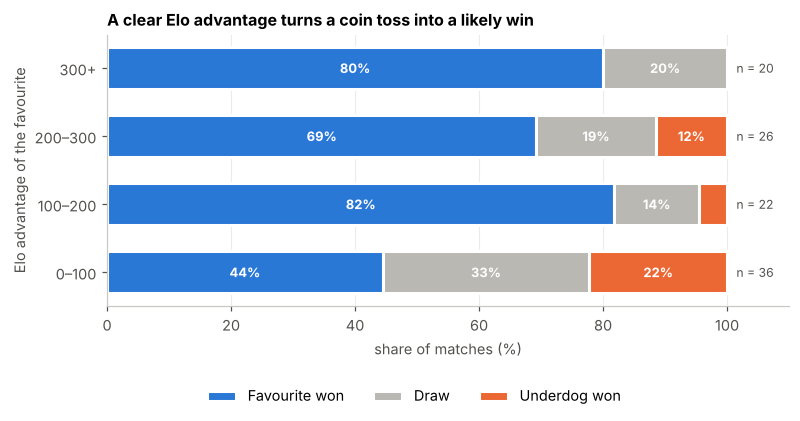

Biggest upsets: the underdog won despite the largest Elo gap


,date,stage,favourite,underdog,elo_gap,fav_gd
match_id,,,,,,
23,2026-06-17,Group,Panama,Ghana,229.0,-1
53,2026-06-24,Group,South Korea,South Africa,222.0,-1
11,2026-06-14,Group,Ecuador,Ivory Coast,213.0,-1
91,2026-07-05,Round of 16,Brazil,Norway,115.0,-1
4,2026-06-12,Group,Paraguay,United States,92.0,-3
56,2026-06-25,Group,Germany,Ecuador,76.0,-1


In [7]:
f1 = team_feats[team_feats.side == 1].set_index('match_id')
f2 = team_feats[team_feats.side == 2].set_index('match_id')
gap = (f1.elo - f2.elo)
mm = matches.set_index('match_id')
fav_gd = np.where(gap >= 0, mm.goals1 - mm.goals2, mm.goals2 - mm.goals1)
story = pd.DataFrame({'favourite': np.where(gap >= 0, f1.team, f2.team), 'underdog': np.where(gap >= 0, f2.team, f1.team),
                      'elo_gap': gap.abs().values, 'fav_gd': fav_gd, 'stage': mm.stage.values, 'date': mm.date.dt.date.values},
                     index=mm.index)
story['outcome'] = np.select([story.fav_gd > 0, story.fav_gd == 0], ['Favourite won', 'Draw'], 'Underdog won')
story['band'] = pd.cut(story.elo_gap, [0, 100, 200, 300, 1000], labels=['0–100', '100–200', '200–300', '300+'], include_lowest=True)
share = pd.crosstab(story.band, story.outcome, normalize='index')[['Favourite won', 'Draw', 'Underdog won']] * 100
counts = story.band.value_counts().sort_index()
display(share.round(1).assign(matches=counts))

fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(len(share)); colours = {'Favourite won': BLUE, 'Draw': GREY, 'Underdog won': ORANGE}
for col in share.columns:
    ax.barh(share.index.astype(str), share[col], left=left, color=colours[col], height=0.62, label=col,
            edgecolor='white', linewidth=2)
    for i, (l, v) in enumerate(zip(left, share[col])):
        if v >= 8:
            ax.text(l + v / 2, i, f'{v:.0f}%', ha='center', va='center', fontsize=8.5, color='white', fontweight='bold')
    left += share[col].values
for i, n in enumerate(counts):
    ax.text(101.5, i, f'n = {n}', va='center', fontsize=8, color=INK)
ax.set(xlim=(0, 110), xlabel='share of matches (%)', ylabel='Elo advantage of the favourite',
       title='A clear Elo advantage turns a coin toss into a likely win')
ax.grid(axis='y', visible=False); ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.45, -0.25))
plt.savefig(f'{OUT}/fig00_story_favourites.png'); plt.show()

print('Biggest upsets: the underdog won despite the largest Elo gap')
display(story[story.outcome == 'Underdog won'].sort_values('elo_gap', ascending=False)
        .head(6)[['date', 'stage', 'favourite', 'underdog', 'elo_gap', 'fav_gd']].round(0))

> ### 📊 Results: the story before the models
> * **The Elo rating clearly carries information.** When the gap is **under 100 points**, the favourite wins only **44%** of matches, draws 33% and loses 22%, so it is close to a coin toss.
> * **Once the gap passes 100 points**, the favourite wins **69–82%** of matches. In the 20 matches with a gap of **300+ points**, the favourite **never lost**.
> * **The pattern is not perfectly smooth.** The 200–300 band (69%) sits a little below the 100–200 band (82%). With only 20–36 matches per band, that dip is within normal chance variation.
> * **Upsets still happen.** The biggest by Elo gap were **Ghana beating Panama**, **South Africa beating South Korea** and **Ivory Coast beating Ecuador**, each against a gap of more than 200 points. The most famous was **Norway knocking out Brazil** in the Round of 16. This is the randomness no pre-match model can remove, and it sets a realistic ceiling for R² later.
> * **This motivates the two models.** Strength differences should explain a good part of the goal difference (2.1), but a large share of the variation will stay unexplained.

## 4 · LR 2.1: predicting the goal difference of a match
### 4.1 Candidate variables, with our expectations written down first
**Data preparation.** One row per match (104). The target is the **goal difference of the match as recorded by FBref** (team 1 − team 2). For the knock-out matches that needed extra time this includes extra-time goals; penalty shoot-outs are not goals and are left out, so a shoot-out counts as a draw.

Because a row describes **two** teams, most candidates are **differences** (team 1 − team 2). Before looking at any data we write down the **sign we expect** for each candidate and **why**. Then the EDA checks those expectations.

In [8]:
t1 = team_feats[team_feats.side == 1].set_index('match_id')
t2 = team_feats[team_feats.side == 2].set_index('match_id')
M = matches.set_index('match_id')

def elo_win_expectancy(row1, row2):
    """Elo expected score of team 1, adding 100 points for a host playing at home."""
    dr = (row1.elo + 100 * row1.host_at_home) - (row2.elo + 100 * row2.host_at_home)
    return 1 / (10 ** (-dr / 400) + 1)

C21 = pd.DataFrame({
    'elo_diff':          t1.elo - t2.elo,
    'elo_win_exp':       [elo_win_expectancy(t1.loc[i], t2.loc[i]) for i in M.index],
    'momentum_diff':     t1.elo_momentum - t2.elo_momentum,
    'form_diff':         t1.form_ppg10 - t2.form_ppg10,
    'attack_diff':       t1.gf_2y - t2.gf_2y,
    'defence_diff':      t1.ga_2y - t2.ga_2y,
    'experience_diff':   t1.wc_experience - t2.wc_experience,
    'rest_diff':         t1.rest_days - t2.rest_days,
    'host_diff':         t1.host_at_home - t2.host_at_home,
    'conf_diff':         t1.strong_conf - t2.strong_conf,
    'wc_gd_sofar_diff':  (t1.wc_gf_sofar - t1.wc_ga_sofar) - (t2.wc_gf_sofar - t2.wc_ga_sofar),
    'is_knockout':       (M.stage != 'Group').astype(int)})
y21 = (M.goals1 - M.goals2).rename('goal_diff')

EXPECT21 = {   # (expected sign, reason) -- written BEFORE looking at the data
    'elo_diff':         (+1, 'stronger team wins by more'),
    'elo_win_exp':      (+1, 'same idea, as a probability, includes host advantage'),
    'momentum_diff':    (+1, 'improving team does better'),
    'form_diff':        (+1, 'better recent results'),
    'attack_diff':      (+1, 'scores more goals in general'),
    'defence_diff':     (-1, 'concedes more goals in general'),
    'experience_diff':  (+1, 'tournament know-how'),
    'rest_diff':        (+1, 'more recovery time'),
    'host_diff':        (+1, 'home crowd, no travel'),
    'conf_diff':        (+1, 'used to tougher opponents'),
    'wc_gd_sofar_diff': (+1, 'in-form during this tournament'),
    'is_knockout':      (-1, 'knock-out games are tighter')}
print('LR 2.1 candidate pool:', C21.shape, '| missing values:', int(C21.isna().sum().sum()))
display(C21.describe().T.round(2))

LR 2.1 candidate pool: (104, 12) | missing values: 0


,count,mean,std,min,25%,50%,75%,max
elo_diff,104.0,52.95,223.15,-496.50,-110.82,51.72,212.80,565.13
elo_win_exp,104.0,0.56,0.25,0.05,0.33,0.57,0.78,0.96
momentum_diff,104.0,-15.56,72.76,-168.97,-66.77,-22.28,47.88,158.45
form_diff,104.0,0.11,0.73,-1.60,-0.40,0.20,0.60,1.80
attack_diff,104.0,0.04,0.67,-1.99,-0.32,0.06,0.50,1.43
defence_diff,104.0,0.02,0.43,-1.14,-0.26,0.02,0.34,0.90
experience_diff,104.0,0.43,1.78,-4.49,-0.71,0.50,1.50,4.73
rest_diff,104.0,0.09,1.52,-8.00,0.00,0.00,1.00,5.00
host_diff,104.0,0.07,0.35,-1.00,0.00,0.00,0.00,1.00
conf_diff,104.0,0.15,0.75,-1.00,0.00,0.00,1.00,1.00


### 4.2 Descriptive statistics of the target

count    104.00
mean       0.48
std        2.02
min       -4.00
25%       -1.00
50%        0.00
75%        2.00
max        6.00
Name: goal_diff, dtype: float64


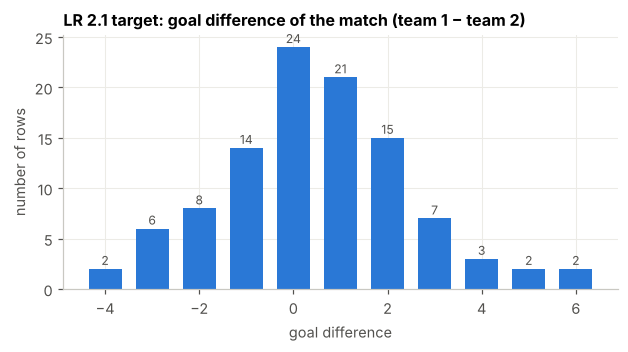

In [9]:
def target_plot(y, title, xlabel, fname, color):
    fig, ax = plt.subplots(figsize=(6.5, 3))
    counts = y.value_counts().sort_index()
    ax.bar(counts.index, counts.values, color=color, width=0.7)
    for x, v in counts.items():
        ax.text(x, v + 0.4, str(v), ha='center', fontsize=8, color=INK)
    ax.set(title=title, xlabel=xlabel, ylabel='number of rows')
    plt.savefig(f'{OUT}/{fname}'); plt.show()

print(y21.describe().round(2))
target_plot(y21, 'LR 2.1 target: goal difference of the match (team 1 − team 2)', 'goal difference', 'fig01_target_21.png', BLUE)

### 4.3 EDA: Pearson correlation, scatter plots and a correlation heatmap
* **Pearson r** measures how strong the straight-line relationship is with the target, from −1 to +1.
* **The p-value** tests H₀: r = 0. A value below 0.05 means the relationship is unlikely to be chance.
* **"Sign as expected"** checks the expectation we wrote down above.

,expected,pearson_r,p_value,sign_as_expected,reason
variable,,,,,
elo_win_exp,+,0.6488,0.0000,True,"same idea, as a probability, includes host adv..."
elo_diff,+,0.6175,0.0000,True,stronger team wins by more
experience_diff,+,0.5656,0.0000,True,tournament know-how
form_diff,+,0.5378,0.0000,True,better recent results
defence_diff,−,-0.3756,0.0001,True,concedes more goals in general
attack_diff,+,0.3617,0.0002,True,scores more goals in general
conf_diff,+,0.3164,0.0011,True,used to tougher opponents
wc_gd_sofar_diff,+,0.3012,0.0019,True,in-form during this tournament
host_diff,+,0.1600,0.1047,True,"home crowd, no travel"


Expectations confirmed by the sign of r: 12 of 12


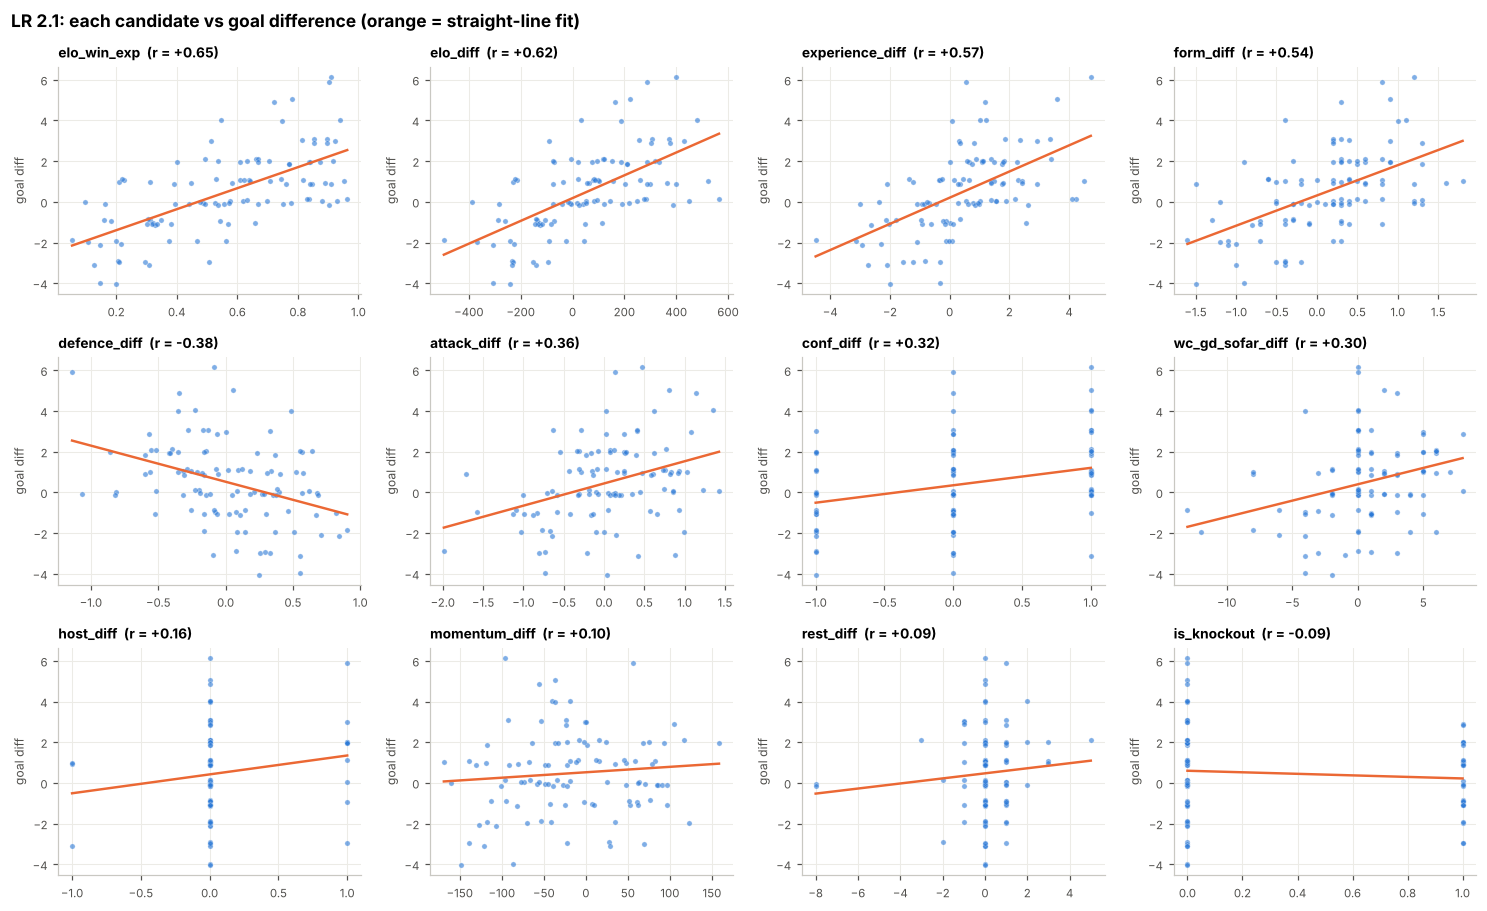

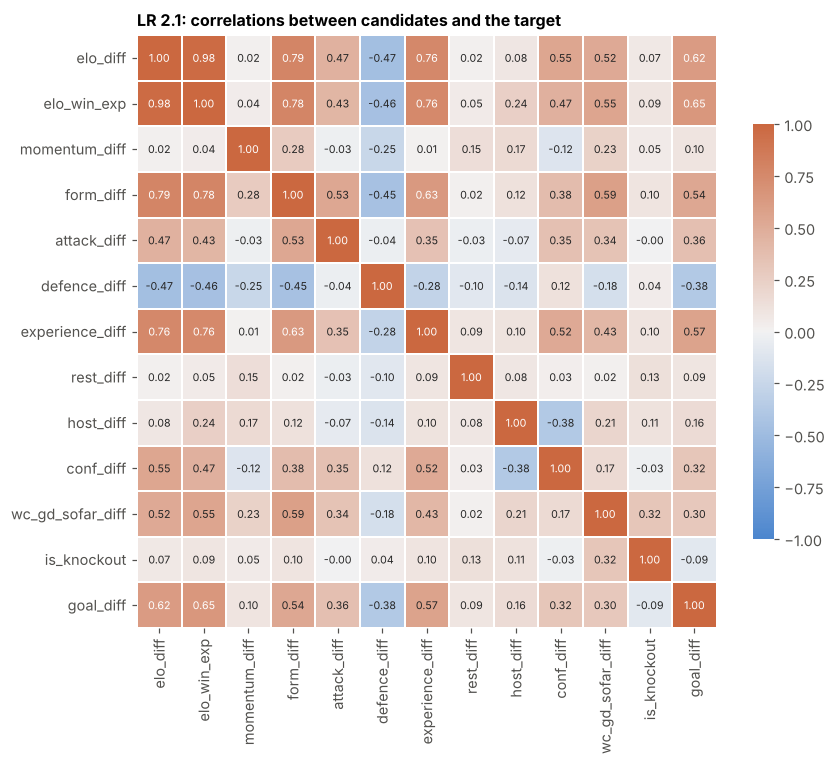

In [10]:
def eda_table(C, y, expect):
    rows = []
    for c in C.columns:
        r, p = stats.pearsonr(C[c], y)
        rows.append({'variable': c, 'expected': '+' if expect[c][0] > 0 else '−', 'pearson_r': r, 'p_value': p,
                     'sign_as_expected': np.sign(r) == expect[c][0], 'reason': expect[c][1]})
    return pd.DataFrame(rows).set_index('variable').sort_values('pearson_r', key=abs, ascending=False)

def scatter_grid(C, y, tab, title, fname, color, ylabel):
    n = len(tab); ncols = 4; nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 2.8 * nrows)); axes = axes.ravel()
    jit = np.random.RandomState(0).uniform(-0.15, 0.15, len(y))   # small jitter: goals are whole numbers
    for ax, c in zip(axes, tab.index):
        ax.scatter(C[c], y + jit, s=12, color=color, alpha=0.6, edgecolor='white', linewidth=0.3)
        b = np.polyfit(C[c], y, 1); xs = np.linspace(C[c].min(), C[c].max(), 20)
        ax.plot(xs, np.polyval(b, xs), color=ORANGE, lw=1.6)
        ax.set_title(f"{c}  (r = {tab.loc[c, 'pearson_r']:+.2f})", fontsize=9); ax.tick_params(labelsize=7.5)
        ax.set_ylabel(ylabel, fontsize=8)
    for ax in axes[n:]:
        ax.axis('off')
    fig.suptitle(title, x=0.01, ha='left', fontweight='bold'); plt.tight_layout()
    plt.savefig(f'{OUT}/{fname}'); plt.show()

def heatmap(C, y, title, fname):
    corr = pd.concat([C, y], axis=1).corr()
    fig, ax = plt.subplots(figsize=(8.5, 7))
    sns.heatmap(corr, cmap=sns.diverging_palette(250, 25, s=75, l=55, as_cmap=True), center=0, vmin=-1, vmax=1,
                annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=1, linecolor='white', cbar_kws={'shrink': .7}, ax=ax)
    ax.set_title(title); plt.savefig(f'{OUT}/{fname}'); plt.show()

tab21 = eda_table(C21, y21, EXPECT21)
display(tab21.round(4))
print('Expectations confirmed by the sign of r:', int(tab21.sign_as_expected.sum()), 'of', len(tab21))
scatter_grid(C21, y21, tab21, 'LR 2.1: each candidate vs goal difference (orange = straight-line fit)', 'fig02_scatter_21.png', BLUE, 'goal diff')
heatmap(C21, y21, 'LR 2.1: correlations between candidates and the target', 'fig03_heatmap_21.png')

> ### 📊 Results: EDA for LR 2.1
> * **The target:** the goal difference ranges from −4 to +6, with a mean of +0.48 and an SD of 2.02. Most matches are decided by 0–2 goals.
> * **All 12 expectations have the expected sign.** The football reasoning was sound.
> * **Strongest relationships** (all p < 0.01):
>   * Elo win expectancy: r = +0.65
>   * Elo difference: r = +0.62
>   * World Cup experience: r = +0.57
>   * recent form: r = +0.54
>   * defence record: r = −0.38
>   * attack record: r = +0.36
>   * confederation: r = +0.32
>   * goal difference so far in the tournament: r = +0.30
> * **Weak relationships** (all p > 0.10): host advantage (r = +0.16), Elo momentum (+0.10), rest days (+0.09) and knock-out stage (−0.09).
> * **The heatmap shows the strength measures overlap a lot.** Elo, experience, form and confederation correlate with each other, because good teams are good on all of them. This is why the next step checks multicollinearity.

### 4.4 Choosing exactly eight variables
**Our written rule:**
1. Rank the candidates by |r| with the target, strongest first.
2. Add them one at a time, but **skip any candidate that would make the variance inflation factor (VIF) ≥ 5**. A high VIF means the candidate is almost a copy of variables already chosen, which makes the coefficients unstable.
3. Stop at eight.

SELECTED (8): ['elo_win_exp', 'experience_diff', 'form_diff', 'defence_diff', 'attack_diff', 'conf_diff', 'wc_gd_sofar_diff', 'momentum_diff']
Skipped because of multicollinearity: ['elo_diff', 'host_diff']
Not needed (weaker): ['rest_diff', 'is_knockout']
Highest VIF among the eight: 4.63


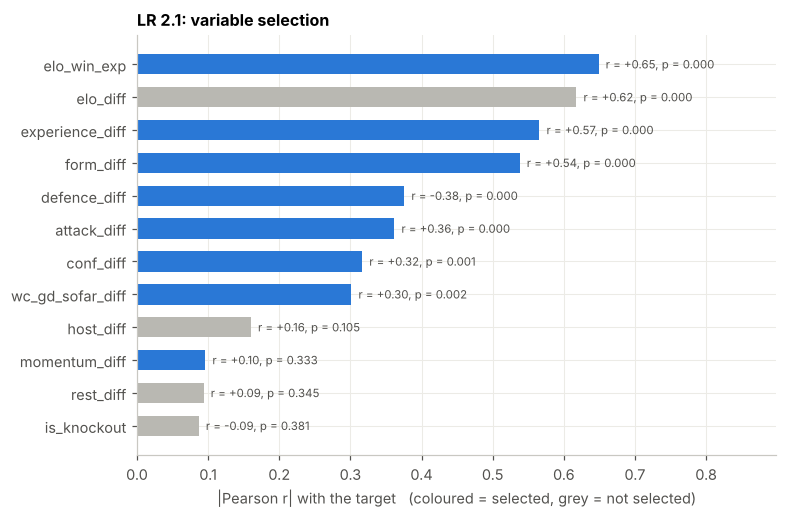

Saved outputs/lr21_dataset.csv (104, 13)


In [11]:
def max_vif(X):
    Xc = sm.add_constant(X).values
    return max(variance_inflation_factor(Xc, i) for i in range(1, Xc.shape[1]))

def choose_eight(C, tab, vif_limit=5):
    chosen, skipped = [], []
    for c in tab.index:
        if len(chosen) == 8:
            break
        if chosen and max_vif(C[chosen + [c]]) >= vif_limit:
            skipped.append(c); continue
        chosen.append(c)
    return chosen, skipped

def selection_chart(tab, chosen, title, fname, color):
    t = tab.iloc[::-1]
    fig, ax = plt.subplots(figsize=(7.5, 0.33 * len(t) + 1))
    ax.barh(t.index, t.pearson_r.abs(), color=[color if v in chosen else GREY for v in t.index], height=0.62)
    for i, (r, p) in enumerate(zip(t.pearson_r, t.p_value)):
        ax.text(abs(r) + 0.01, i, f'r = {r:+.2f}, p = {p:.3f}', va='center', fontsize=7.5, color=INK)
    ax.set_xlim(0, t.pearson_r.abs().max() + 0.25)
    ax.set(title=title, xlabel='|Pearson r| with the target   (coloured = selected, grey = not selected)')
    plt.savefig(f'{OUT}/{fname}'); plt.show()

F21, skipped21 = choose_eight(C21, tab21)
print('SELECTED (8):', F21)
print('Skipped because of multicollinearity:', skipped21)
print('Not needed (weaker):', [c for c in tab21.index if c not in F21 + skipped21])
print('Highest VIF among the eight: %.2f' % max_vif(C21[F21]))
selection_chart(tab21, F21, 'LR 2.1: variable selection', 'fig04_selection_21.png', BLUE)

D21 = pd.concat([M[['team1', 'team2', 'stage']], C21[F21], y21], axis=1).reset_index()
assert len(D21) == 104 and len(F21) == 8
D21.to_csv(f'{OUT}/lr21_dataset.csv', index=False)
print('Saved', f'{OUT}/lr21_dataset.csv', D21.shape)

> ### 📊 Results: the eight variables for LR 2.1
> * **Selected:** `elo_win_exp`, `experience_diff`, `form_diff`, `defence_diff`, `attack_diff`, `conf_diff`, `wc_gd_sofar_diff`, `momentum_diff`.
> * **`elo_diff` was skipped:** it is almost the same information as `elo_win_exp`, so adding it would push the VIF above 5.
> * **`host_diff` was skipped:** host advantage is already built into `elo_win_exp`, which adds 100 Elo points for a host playing at home.
> * **The eighth place went to `momentum_diff`** (r = +0.10), just ahead of `is_knockout` (r = −0.09). Once extra-time goals are counted, knock-out matches are hardly tighter than group matches, so the stage flag carries almost no signal.
> * **The highest VIF is 4.63**, so multicollinearity is acceptable. The 104-row dataset is saved.

### 4.5 Fit the multiple linear regression (OLS)
`goal_diff = b0 + b1·x1 + … + b8·x8 + error`.

Each coefficient means: **holding the other seven variables fixed**, a one-unit increase in this variable changes the expected goal difference by `b`. We use robust (HC3) standard errors, which stay valid if the errors are not equally spread.

                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -1.7077      0.650     -2.627      0.009      -2.982      -0.434
elo_win_exp          3.8629      1.239      3.117      0.002       1.434       6.292
experience_diff      0.2277      0.150      1.518      0.129      -0.066       0.522
form_diff           -0.1662      0.493     -0.337      0.736      -1.133       0.800
defence_diff        -0.5457      0.543     -1.004      0.315      -1.611       0.519
attack_diff          0.4510      0.333      1.356      0.175      -0.201       1.103
conf_diff           -0.0087      0.285     -0.030      0.976      -0.567       0.550
wc_gd_sofar_diff    -0.0584      0.057     -1.026      0.305      -0.170       0.053
momentum_diff        0.0025      0.002      1.070      0.284      -0.002       0.007
R² = 0.468 | adjusted R² = 0.423 | F-test p = 5.79e-08


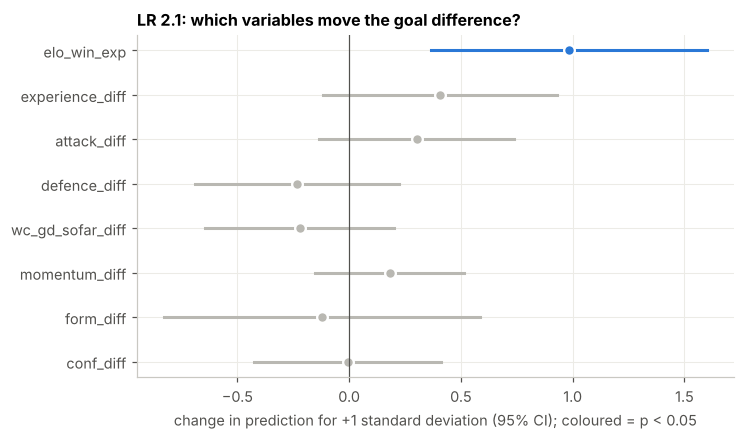

In [12]:
X21, Y21 = D21[F21], D21['goal_diff']
ols21 = sm.OLS(Y21, sm.add_constant(X21)).fit(cov_type='HC3')
print(ols21.summary().tables[1])
print(f'R² = {ols21.rsquared:.3f} | adjusted R² = {ols21.rsquared_adj:.3f} | F-test p = {ols21.f_pvalue:.2e}')

def coef_plot(res, title, fname, color):
    """Standardised coefficients: effect of a one-standard-deviation change, so variables can be compared."""
    X = res.model.exog[:, 1:]; names = res.model.exog_names[1:]
    sd = X.std(axis=0, ddof=1)
    b = res.params[names].values * sd
    lo, hi = res.conf_int().loc[names, 0].values * sd, res.conf_int().loc[names, 1].values * sd
    order = np.argsort(np.abs(b))
    fig, ax = plt.subplots(figsize=(7, 0.38 * len(names) + 1))
    for i, j in enumerate(order):
        sig = res.pvalues[names[j]] < 0.05
        ax.plot([lo[j], hi[j]], [i, i], color=color if sig else GREY, lw=2)
        ax.plot(b[j], i, 'o', color=color if sig else GREY, ms=7, mec='white', mew=1.5)
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_yticks(range(len(names))); ax.set_yticklabels([names[j] for j in order])
    ax.set(title=title, xlabel='change in prediction for +1 standard deviation (95% CI); coloured = p < 0.05')
    plt.savefig(f'{OUT}/{fname}'); plt.show()

coef_plot(ols21, 'LR 2.1: which variables move the goal difference?', 'fig05_coefs_21.png', BLUE)

> ### 📊 Results: OLS for goal difference
> * **Overall fit:** R² = 0.468 and adjusted R² = 0.423. The F-test gives p ≈ 6×10⁻⁸, so together the eight variables clearly explain the goal difference.
> * **`elo_win_exp` is the one clearly significant variable:** b = 3.86 (95% CI 1.43 to 6.29, p = 0.002). A 10-percentage-point higher Elo win expectancy adds about **0.39 goals** to the expected margin, holding the other variables fixed.
> * **The other seven are not significant** once Elo is in the model (p from 0.13 to 0.98), even though experience, form, attack and defence each correlated strongly on their own. **Elo already contains most of their information**, because a rating built from results reflects a team's form, attack, defence and quality of opposition.
> * **World Cup experience is the closest to significance** (b = 0.23, p = 0.13).
> * **The coefficient plot** shows each variable's effect for a one-standard-deviation change. Only the coloured variable has an interval that does not cross zero.

### 4.6 Evaluate on unseen matches: predicted vs true
* **Hold-out test.** Train on a random 75% of the matches, predict the other 25% (26 matches), and compare the predictions with the true values.
* **Baseline.** A "no-skill" model that always predicts the training average. Our model must beat it.
* **Repeated 5-fold cross-validation (10 repeats, 50 test sets).** One split of 26 matches is noisy, so we also average over many splits.

**Metrics:**
* **RMSE:** the typical error in goals. Lower is better.
* **MAE:** the average absolute error. Lower is better.
* **R²:** the share of variation explained, measured on unseen data.

HOLD-OUT TEST (26 unseen matches)


,RMSE,MAE,R2
Linear regression,1.755,1.458,0.437
Mean baseline,2.342,1.809,-0.003


REPEATED 5-FOLD CV (mean of 50 test sets):


,RMSE,MAE,R2
Linear regression,1.617,1.293,0.292


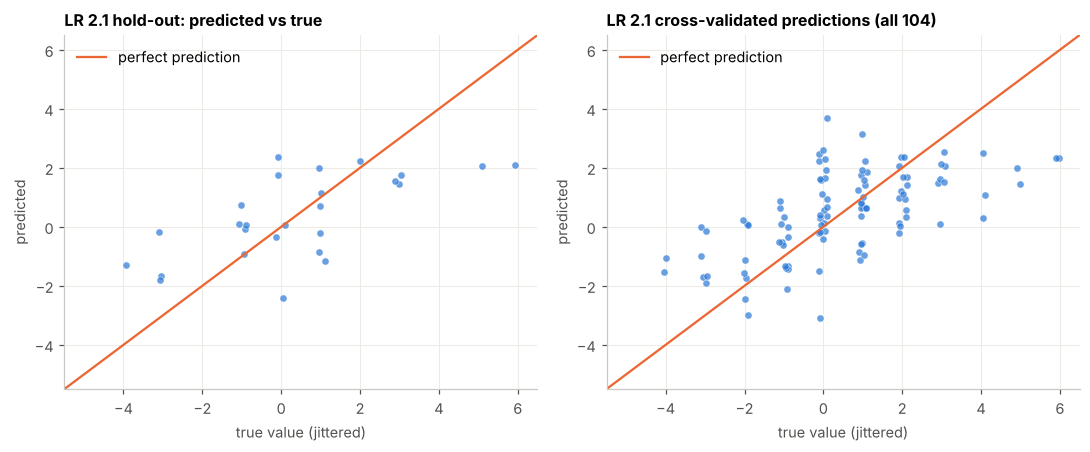

In [13]:
def scores(y_true, y_pred):
    return {'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)), 'MAE': mean_absolute_error(y_true, y_pred), 'R2': r2_score(y_true, y_pred)}

def cross_validate(model, X, y, splits):
    res, oof, cnt = [], np.zeros(len(y)), np.zeros(len(y))
    for tr, te in splits:
        m = clone(model).fit(X.iloc[tr], y.iloc[tr]); p = m.predict(X.iloc[te])
        res.append(scores(y.iloc[te], p)); oof[te] += p; cnt[te] += 1
    return pd.DataFrame(res), oof / cnt

def pred_vs_true(ax, y_true, y_pred, title, color, lim):
    jit = np.random.RandomState(1).uniform(-0.12, 0.12, len(y_true))
    ax.scatter(np.asarray(y_true) + jit, y_pred, s=22, color=color, alpha=0.7, edgecolor='white', linewidth=0.4)
    ax.plot(lim, lim, color=ORANGE, lw=1.5, label='perfect prediction')
    ax.set(xlim=lim, ylim=lim, title=title, xlabel='true value (jittered)', ylabel='predicted'); ax.legend(loc='upper left')

linreg = LinearRegression()
Xtr, Xte, ytr, yte = train_test_split(X21, Y21, test_size=0.25, random_state=SEED)
p_lin = clone(linreg).fit(Xtr, ytr).predict(Xte)
p_base = DummyRegressor().fit(Xtr, ytr).predict(Xte)
hold21 = pd.DataFrame({'Linear regression': scores(yte, p_lin), 'Mean baseline': scores(yte, p_base)}).T
print('HOLD-OUT TEST (26 unseen matches)'); display(hold21.round(3))

splits21 = list(RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED).split(X21))
cv21, oof21 = cross_validate(linreg, X21, Y21, splits21)
print('REPEATED 5-FOLD CV (mean of 50 test sets):'); display(cv21.mean().round(3).to_frame('Linear regression').T)

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
pred_vs_true(ax[0], yte, p_lin, 'LR 2.1 hold-out: predicted vs true', BLUE, (-5.5, 6.5))
pred_vs_true(ax[1], Y21, oof21, 'LR 2.1 cross-validated predictions (all 104)', BLUE, (-5.5, 6.5))
plt.tight_layout(); plt.savefig(f'{OUT}/fig06_pred_vs_true_21.png'); plt.show()

> ### 📊 Results: predicted vs true goal difference
> * **Hold-out test on 26 unseen matches:** R² = 0.437 and RMSE = 1.76 goals, against the baseline's RMSE of 2.34 and R² of about 0. That is a **25% smaller error** than guessing the average.
> * **Repeated 5-fold CV over 50 test sets:** R² = 0.292, RMSE = 1.62 and MAE = 1.29. The CV figure is the more reliable estimate, because one split of 26 matches is noisy.
> * **R² falls from 0.47 on the fitted data to 0.29 on unseen data.** This shows **some overfitting**, which is expected with 8 variables and only 104 matches.
> * **The plots show predictions rising with the true margin but squeezed towards zero.** The model never predicts a 5- or 6-goal win, because big wins are rare and partly down to luck.

### 4.6b Where did the model get it most wrong?
Using the cross-validated predictions, where each match was predicted by a model that had **not** seen it, we list the matches with the biggest errors. This shows *what kind* of match the model cannot foresee.

In [14]:
err21 = D21[['match_id', 'stage', 'team1', 'team2', 'goal_diff']].copy()
err21['predicted'] = oof21.round(2)
err21['error'] = (err21.goal_diff - err21.predicted).round(2)
print('Five biggest surprises (true − predicted goal difference):')
display(err21.reindex(err21.error.abs().sort_values(ascending=False).index).head(5))
print('Share of matches where the model picked the right winner or draw side (sign of goal difference):',
      f"{(np.sign(err21.predicted.round()) == np.sign(err21.goal_diff)).mean():.0%}")

Five biggest surprises (true − predicted goal difference):


,match_id,stage,team1,team2,goal_diff,predicted,error
11,12,Group,Sweden,Tunisia,4,0.30,3.70
13,14,Group,Spain,Cape Verde,0,3.69,-3.69
26,27,Group,Canada,Qatar,6,2.32,3.68
8,9,Group,Germany,Curaçao,6,2.35,3.65
61,62,Group,Senegal,Iraq,5,1.44,3.56


Share of matches where the model picked the right winner or draw side (sign of goal difference): 63%


> ### 📊 Results: biggest surprises
> * **Four of the five biggest errors are thrashings bigger than expected:** Sweden 4–0 Tunisia (predicted +0.3), Canada 6–0 Qatar (+2.3), Germany 6–0 Curaçao (+2.4) and Senegal 5–0 Iraq (+1.4). The model saw the right winner each time but could not foresee the size of the win.
> * **The fifth is the opposite:** Spain's 0–0 draw with Cape Verde, where the model expected Spain to win by almost 4 goals.
> * **No variable built before kick-off can capture a red card, an early goal or an off day.** These matches are the main reason the unseen-data R² stays around 0.3.
> * **The model calls the right side of the result in 63% of matches** (team 1 wins, draw or team 2 wins), well above a three-way guess (33%).

### 4.7 Optimising the linear regression step by step
We now try to improve the linear model with the standard sequence of optimisation steps. Each step is added **on top of** the previous one:

| Step | What it does | Why it might help |
|---|---|---|
| 0 | Baseline OLS with the 8 variables | starting point |
| 1 | Remove outliers in the **training** response (1.5 × IQR rule) | extreme scores can pull the line |
| 2 | Check for non-linear relationships (Ramsey RESET test plus the scatter plots) | a straight line may be the wrong shape |
| 3 | Check multicollinearity (VIF of the 8 variables) | overlapping variables make coefficients unstable |
| 4 | Yeo-Johnson transformation of the explanatory variables | makes skewed variables more symmetric |
| 5 | Z-standardisation | puts all coefficients on the same scale |

**How we judge each step.** Every step is fitted **on the training part only** and then applied to the untouched test part. Outliers are never removed from the test part, so every stage is scored on the same matches. Instead of one train/test split, we score each stage on **the same 50 cross-validation splits** used above, so a step is only kept if it helps reliably, not by luck.

LR 2.1 step 2 - Ramsey RESET test (H0: the linear form is adequate): F = 0.070, p = 0.792
LR 2.1 step 3 - VIF of each variable (rule: < 5 is acceptable)


,elo_win_exp,experience_diff,form_diff,defence_diff,attack_diff,conf_diff,wc_gd_sofar_diff,momentum_diff
VIF,4.63,2.57,4.1,1.85,1.58,1.83,1.79,1.33


LR 2.1 step 1 - rows outside 1.5 x IQR of the response in the full data: 0 (bounds -5.5 to 6.5)


,train R²,test R²,test RMSE,test MAE,p vs baseline
stage,,,,,
0. Baseline OLS,0.4790,0.2919,1.6171,1.2926,NaN
1. + Outlier removal,0.4748,0.2857,1.6253,1.2983,0.6846
2. + Non-linearity check,0.4748,0.2857,1.6253,1.2983,0.6846
3. + Multicollinearity check,0.4748,0.2857,1.6253,1.2983,0.6846
4. + Yeo-Johnson,0.4701,0.2760,1.6352,1.3022,0.3926
5. + Z-standardisation,0.4701,0.2760,1.6352,1.3022,0.3926


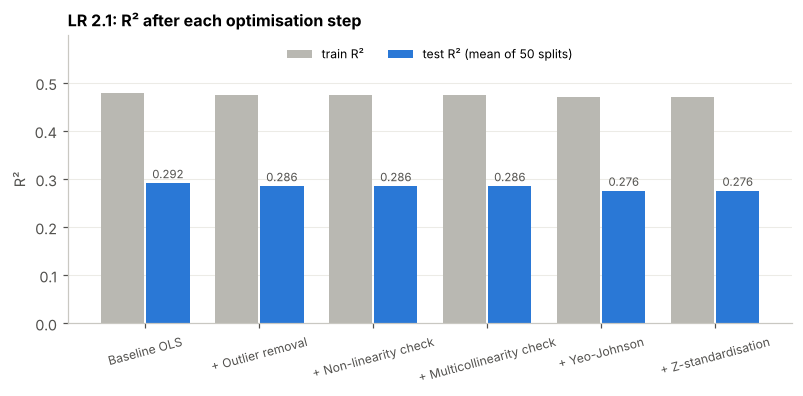

Fitted regression equation:
goal_diff = -1.7077 + 3.8629·elo_win_exp + 0.2277·experience_diff − 0.1662·form_diff − 0.5457·defence_diff + 0.4510·attack_diff − 0.0087·conf_diff − 0.0584·wc_gd_sofar_diff + 0.0025·momentum_diff


In [15]:
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import PowerTransformer
from statsmodels.stats.diagnostic import linear_reset

class OptimisedOLS(BaseEstimator, RegressorMixin):
    """OLS with the optional optimisation steps. All steps are learned from the training data only."""
    def __init__(self, trim=False, yeo_johnson=False, standardise=False):
        self.trim, self.yeo_johnson, self.standardise = trim, yeo_johnson, standardise
    def _prep(self, X, fit):
        X = np.asarray(X, dtype=float)
        if self.yeo_johnson:
            X = self.yj_.fit_transform(X) if fit else self.yj_.transform(X)
        if self.standardise:
            X = self.sc_.fit_transform(X) if fit else self.sc_.transform(X)
        return X
    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        if self.trim:                                             # step 1: IQR rule on the TRAINING response
            q1, q3 = np.percentile(y, [25, 75]); iqr = q3 - q1
            keep = (y >= q1 - 1.5 * iqr) & (y <= q3 + 1.5 * iqr)
            X, y = X[keep], y[keep]; self.n_removed_ = int((~keep).sum())
        self.yj_, self.sc_ = PowerTransformer(method='yeo-johnson', standardize=False), StandardScaler()
        self.lr_ = LinearRegression().fit(self._prep(X, fit=True), y)
        return self
    def predict(self, X):
        return self.lr_.predict(self._prep(X, fit=False))

def corrected_ttest(rmse_a, rmse_b, n_train, n_test):
    """Corrected resampled t-test for repeated cross-validation. Negative mean = model A has lower RMSE."""
    d = np.asarray(rmse_a) - np.asarray(rmse_b); k = len(d)
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * d.var(ddof=1))
    return d.mean(), t, 2 * stats.t.sf(abs(t), k - 1)

STAGES = {
    '0. Baseline OLS':                  OptimisedOLS(),
    '1. + Outlier removal':             OptimisedOLS(trim=True),
    '2. + Non-linearity check':         OptimisedOLS(trim=True),       # a check: no change to the model
    '3. + Multicollinearity check':     OptimisedOLS(trim=True),       # a check: no change to the model
    '4. + Yeo-Johnson':                 OptimisedOLS(trim=True, yeo_johnson=True),
    '5. + Z-standardisation':           OptimisedOLS(trim=True, yeo_johnson=True, standardise=True)}

def run_stages(X, y, splits, title, fname, color):
    rows = []
    for stage, est in STAGES.items():
        tr_r2, te = [], []
        for tr, tst in splits:
            m = clone(est).fit(X.iloc[tr], y.iloc[tr])
            tr_r2.append(r2_score(y.iloc[tr], m.predict(X.iloc[tr])))
            te.append(scores(y.iloc[tst], m.predict(X.iloc[tst])))
        te = pd.DataFrame(te)
        rows.append({'stage': stage, 'train R²': np.mean(tr_r2), 'test R²': te.R2.mean(), 'test RMSE': te.RMSE.mean(),
                     'test MAE': te.MAE.mean(), '_rmse': te.RMSE.values})
    tab = pd.DataFrame(rows).set_index('stage')
    base = tab['_rmse'].iloc[0]; n_test, n_train = len(splits[0][1]), len(splits[0][0])
    tab['p vs baseline'] = [np.nan] + [corrected_ttest(r, base, n_train, n_test)[2] if not np.allclose(r, base) else np.nan
                                       for r in tab['_rmse'].iloc[1:]]
    tab = tab.drop(columns='_rmse')
    display(tab.round(4))
    fig, ax = plt.subplots(figsize=(8.5, 3.4)); xx = np.arange(len(tab))
    ax.bar(xx - 0.2, tab['train R²'], 0.38, color=GREY, label='train R²')
    ax.bar(xx + 0.2, tab['test R²'], 0.38, color=color, label='test R² (mean of 50 splits)')
    for i, v in enumerate(tab['test R²']):
        ax.text(i + 0.2, v + 0.01, f'{v:.3f}', ha='center', fontsize=7.5, color=INK)
    ax.set_xticks(xx); ax.set_xticklabels([s.split('. ')[1] for s in tab.index], fontsize=8, rotation=15)
    ax.set(title=title, ylabel='R²', ylim=(0, max(tab['train R²']) * 1.25)); ax.legend(fontsize=8, ncol=2, loc='upper center'); ax.grid(axis='x', visible=False)
    plt.savefig(f'{OUT}/{fname}'); plt.show()
    return tab

def checks(X, y, ols_res, name):
    """Step 2 and 3 evidence: Ramsey RESET test for non-linearity and the VIF of every variable."""
    reset = linear_reset(sm.OLS(y, sm.add_constant(X)).fit(), power=2, use_f=True)
    print(f'{name} step 2 - Ramsey RESET test (H0: the linear form is adequate): F = {float(reset.fvalue):.3f}, p = {float(reset.pvalue):.3f}')
    Xc = sm.add_constant(X)
    vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=X.columns, name='VIF')
    print(f'{name} step 3 - VIF of each variable (rule: < 5 is acceptable)'); display(vif.round(2).to_frame().T)
    q1, q3 = np.percentile(y, [25, 75]); iqr = q3 - q1
    out = ((y < q1 - 1.5 * iqr) | (y > q3 + 1.5 * iqr)).sum()
    print(f'{name} step 1 - rows outside 1.5 x IQR of the response in the full data: {out} (bounds {q1 - 1.5 * iqr:.1f} to {q3 + 1.5 * iqr:.1f})')

def print_equation(res, target):
    eq = f'{target} = {res.params["const"]:.4f}'
    for v, b in res.params.drop('const').items():
        eq += f' {"+" if b >= 0 else "−"} {abs(b):.4f}·{v}'
    print('Fitted regression equation:\n' + eq)

checks(X21, Y21, ols21, 'LR 2.1')
opt21 = run_stages(X21, Y21, splits21, 'LR 2.1: R² after each optimisation step', 'fig07a_optimisation_21.png', BLUE)
print_equation(ols21, 'goal_diff')

> ### 📊 Results: optimisation of LR 2.1
> * **Step 1, outliers:** in the full data no match lies outside the 1.5 × IQR bounds (−5.5 to +6.5). A few big wins fall outside inside some training folds and are removed there, but this makes the test error slightly **worse** (RMSE 1.617 → 1.625).
> * **Step 2, non-linearity:** the Ramsey RESET test gives **p = 0.79**, so there is no evidence that a straight line is the wrong shape. The scatter plots in 4.3 agree.
> * **Step 3, multicollinearity:** every VIF is below 5. The highest is 4.63 for `elo_win_exp`. No variable needs to be removed.
> * **Steps 4–5, Yeo-Johnson and z-standardisation:** these make the test R² slightly **lower** (0.292 → 0.276). Z-standardisation never changes the predictions, only the scale of the coefficients.
> * **None of the steps improves on the baseline** (all p > 0.39).
> * **Decision:** keep the **baseline OLS** as the final LR 2.1 model. Its variables are already roughly symmetric and linearly related to the goal difference, so the extra steps only add complexity.
>
> **Final LR 2.1 model:** goal_diff = −1.708 + 3.863·elo_win_exp + 0.228·experience_diff − 0.166·form_diff − 0.546·defence_diff + 0.451·attack_diff − 0.009·conf_diff − 0.058·wc_gd_sofar_diff + 0.0025·momentum_diff

### 4.8 Competing algorithms
We compare linear regression with seven other scikit-learn regressors **on exactly the same 50 train/test splits**, so the comparison is fair:
* **Ridge** and **Lasso:** linear regression with a penalty that shrinks unhelpful coefficients. Lasso can switch variables off completely.
* **k-nearest neighbours:** predicts from the most similar past matches.
* **Support vector regression (RBF kernel):** fits a flexible curve and ignores small errors inside a margin.
* **Random forest** and **gradient boosting:** many decision trees, which can capture non-linear effects.
* **Mean baseline:** always predicts the average.

Then we test whether the best competitor is **really** better than linear regression. A paired t-test on the 50 RMSE values would ignore that the training sets overlap, so we use a **corrected resampled t-test**, which widens the standard error to allow for it.

To make the comparison **systematic**, the hyperparameters of every competitor (penalty strength, number of neighbours, tree depth and so on) are first tuned with a grid search. This gives each competitor its best chance. If linear regression still holds its own, that is strong evidence for it.

Step 1: hyperparameter tuning (5-fold grid search)


,best hyperparameters,tuning RMSE
model,,
k-nearest neighbours,"{'n_neighbors': 20, 'weights': 'distance'}",1.591
Support vector regression,"{'C': 1, 'epsilon': 0.1, 'gamma': 0.03}",1.590
Random forest,"{'max_depth': 3, 'min_samples_leaf': 10}",1.643
Gradient boosting,"{'learning_rate': 0.03, 'max_depth': 1, 'n_est...",1.614


Step 2: all models on the same 50 cross-validation splits


,RMSE,RMSE_se,MAE,R2
Support vector regression,1.570,0.034,1.215,0.345
k-nearest neighbours,1.588,0.032,1.279,0.329
Ridge,1.593,0.030,1.264,0.320
Lasso,1.598,0.031,1.263,0.316
Random forest,1.604,0.029,1.287,0.303
Gradient boosting,1.611,0.031,1.277,0.304
Linear regression,1.617,0.031,1.293,0.292
Mean baseline,2.019,0.039,1.592,-0.072


Is each model different from linear regression? (corrected t-test on RMSE)


,RMSE − linear RMSE,t,p_value
model,,,
Support vector regression,-0.047,-0.756,0.453
k-nearest neighbours,-0.029,-0.460,0.647
Ridge,-0.024,-0.626,0.534
Lasso,-0.020,-0.542,0.590
Random forest,-0.013,-0.186,0.853
Gradient boosting,-0.006,-0.100,0.921
Mean baseline,0.401,3.680,0.001


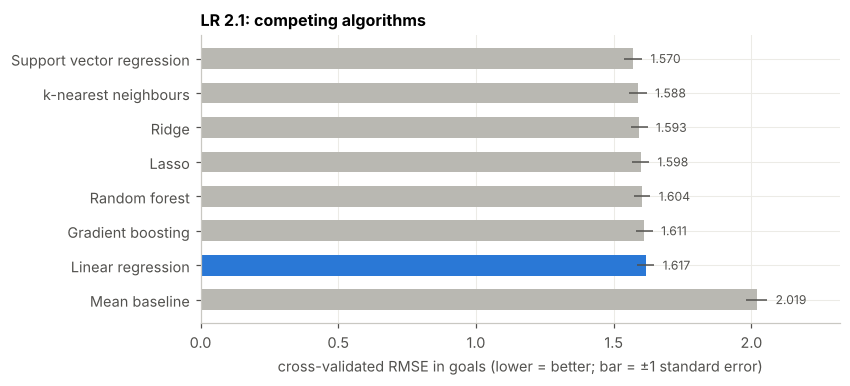

In [16]:
from sklearn.model_selection import GridSearchCV, KFold, GroupKFold
from sklearn.svm import SVR

GRIDS = {   # model -> (estimator, hyperparameter grid)
    'k-nearest neighbours': (make_pipeline(StandardScaler(), KNeighborsRegressor()),
                             {'kneighborsregressor__n_neighbors': [5, 10, 15, 20, 30], 'kneighborsregressor__weights': ['uniform', 'distance']}),
    'Support vector regression': (make_pipeline(StandardScaler(), SVR(kernel='rbf')),
                                  {'svr__C': [0.3, 1, 3, 10], 'svr__epsilon': [0.1, 0.5, 1.0], 'svr__gamma': ['scale', 0.03]}),
    'Random forest': (RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
                      {'max_depth': [2, 3, 5, None], 'min_samples_leaf': [3, 5, 10]}),
    'Gradient boosting': (GradientBoostingRegressor(subsample=0.8, random_state=SEED),
                          {'n_estimators': [50, 100, 200], 'max_depth': [1, 2, 3], 'learning_rate': [0.03, 0.1]})}

def tune(X, y, groups=None):
    """Grid-search each competitor's hyperparameters with 5-fold CV (grouped by match when groups are given)."""
    cv = list(GroupKFold(n_splits=5).split(X, y, groups)) if groups is not None else KFold(5, shuffle=True, random_state=SEED)
    tuned, rows = {}, []
    for name, (est, grid) in GRIDS.items():
        gs = GridSearchCV(est, grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X, y)
        tuned[name] = gs.best_estimator_
        rows.append({'model': name, 'best hyperparameters': {k.split('__')[-1]: v for k, v in gs.best_params_.items()},
                     'tuning RMSE': -gs.best_score_})
    display(pd.DataFrame(rows).set_index('model').round(3))
    return tuned

def competitors(tuned, extra=None):
    models = {
        'Linear regression': LinearRegression(),
        'Ridge': make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 40))),     # penalty tuned internally
        'Lasso': make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=SEED, max_iter=50000)),
        **{n: clone(m) for n, m in tuned.items()},
        **(extra or {}),
        'Mean baseline': DummyRegressor()}
    return models

def compare_models(models, X, y, splits, title, fname, color):
    raw = {name: cross_validate(m, X, y, splits)[0] for name, m in models.items()}
    table = pd.DataFrame({n: {'RMSE': s.RMSE.mean(), 'RMSE_se': s.RMSE.std() / np.sqrt(len(s)), 'MAE': s.MAE.mean(), 'R2': s.R2.mean()}
                          for n, s in raw.items()}).T.sort_values('RMSE')
    n_test = len(splits[0][1]); n_train = len(splits[0][0])
    tests = []
    for n in table.index.drop('Linear regression'):
        diff, t, p = corrected_ttest(raw[n].RMSE, raw['Linear regression'].RMSE, n_train, n_test)
        tests.append({'model': n, 'RMSE − linear RMSE': diff, 't': t, 'p_value': p})
    display(table.round(3))
    print('Is each model different from linear regression? (corrected t-test on RMSE)')
    display(pd.DataFrame(tests).set_index('model').round(3))
    t = table.iloc[::-1]
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.barh(t.index, t.RMSE, xerr=t.RMSE_se, color=[color if n == 'Linear regression' else GREY for n in t.index], height=0.6,
            error_kw={'ecolor': INK, 'lw': 1})
    for i, (v, se) in enumerate(zip(t.RMSE, t.RMSE_se)):
        ax.text(v + se + 0.03, i, f'{v:.3f}', va='center', fontsize=8, color=INK)
    ax.set(title=title, xlabel='cross-validated RMSE in goals (lower = better; bar = ±1 standard error)')
    ax.set_xlim(0, t.RMSE.max() * 1.15)
    plt.savefig(f'{OUT}/{fname}'); plt.show()
    return table

print('Step 1: hyperparameter tuning (5-fold grid search)')
tuned21 = tune(X21, Y21)
print('Step 2: all models on the same 50 cross-validation splits')
comp21 = compare_models(competitors(tuned21), X21, Y21, splits21, 'LR 2.1: competing algorithms', 'fig07_competing_21.png', BLUE)

> ### 📊 Results and recommendation: competing algorithms for LR 2.1
> * **Tuning:** the grid search chose simple settings for every flexible model, for example random forest with trees only **3 levels deep** and gradient boosting with **depth-1 trees**. This tells us the data supports only simple patterns.
> * **Cross-validated RMSE** on the same 50 splits (lower is better):
>
>   | Model | RMSE | R² |
>   |---|---|---|
>   | Support vector regression | 1.570 | 0.345 |
>   | k-nearest neighbours | 1.588 | 0.329 |
>   | Ridge | 1.593 | 0.320 |
>   | Lasso | 1.598 | 0.316 |
>   | Random forest | 1.604 | 0.303 |
>   | Gradient boosting | 1.611 | 0.304 |
>   | **Linear regression** | **1.617** | **0.292** |
>   | Mean baseline | 2.019 | −0.072 |
> * **No competitor is significantly better than linear regression.** The corrected t-test gives p from 0.45 to 0.92. The best model, SVR, lowers the error by only **0.05 goals**, about 3%, and that gain is within chance. All seven real models sit within 0.05 goals of each other. Only the mean baseline is significantly worse (p = 0.001).
> * **The comparison slightly favours the competitors.** Their hyperparameters were tuned on all 104 matches before the 50 test splits, so their scores are, if anything, a little optimistic. That makes linear regression holding its own a stronger result.
> * **Recommendation:** use **multiple linear regression (OLS)** for this task.
>   * Its accuracy is statistically equal to every alternative.
>   * Each coefficient has a direct football meaning with a p-value, for example "+10 points of win expectancy gives about +0.39 goals". SVR and k-NN cannot give that.
>   * With 104 matches, the simpler model is the safer choice.
>
>   **If pure prediction accuracy mattered most**, SVR or Ridge would be the next to try, and the comparison should be repeated on a larger dataset, such as several World Cups, to see whether their small advantage becomes real.

## 5 · LR 2.2: predicting the goals scored by a team
### 5.1 Candidate variables
**Data preparation.** Each match becomes **two rows**, one for each team (208 rows). The target is the goals **that team** scored in the match (FBref score).

The variables are written from the team's point of view: the team's own strength and attack, plus the **opponent's** strength and defence. We use **level** variables (team value, opponent value) instead of the **differences** used in LR 2.1, so the two models stay distinct. The brief allows at most 4 shared variables.

We also add one **engineered interaction**, `attack_vs_defence` = team's goals scored per game × opponent's goals conceded per game. The idea is that a strong attack scores most against a weak defence.

LR 2.2 candidate pool: (208, 14) | missing values: 0
count    208.00
mean       1.48
std        1.39
min        0.00
25%        0.00
50%        1.00
75%        2.00
max        7.00
Name: goals, dtype: float64


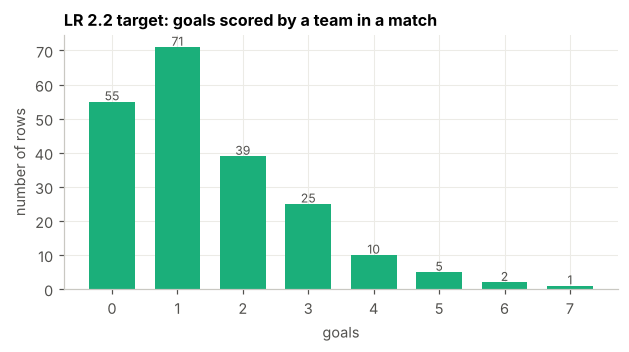

In [17]:
T = team_feats.set_index(['match_id', 'side'])
O = team_feats.assign(side=3 - team_feats.side).set_index(['match_id', 'side'])  # opponent's values, aligned to the team's row
O = O.loc[T.index]
stage = matches.set_index('match_id').loc[T.index.get_level_values(0), 'stage'].values
goals = np.where(T.index.get_level_values(1) == 1,
                 matches.set_index('match_id').loc[T.index.get_level_values(0), 'goals1'].values,
                 matches.set_index('match_id').loc[T.index.get_level_values(0), 'goals2'].values)

C22 = pd.DataFrame({
    'team_elo':          T.elo.values,
    'opp_elo':           O.elo.values,
    'team_form':         T.form_ppg10.values,
    'opp_form':          O.form_ppg10.values,
    'team_attack':       T.gf_2y.values,
    'opp_defence':       O.ga_2y.values,
    'attack_vs_defence': (T.gf_2y * O.ga_2y).values,
    'team_momentum':     T.elo_momentum.values,
    'team_experience':   T.wc_experience.values,
    'team_rest':         T.rest_days.values,
    'team_host_home':    T.host_at_home.values,
    'team_wc_goals_sofar': T.wc_gf_sofar.values,
    'opp_wc_conceded_sofar': O.wc_ga_sofar.values,
    'is_knockout':       (stage != 'Group').astype(int)})
y22 = pd.Series(goals, name='goals')
groups22 = pd.Series(T.index.get_level_values(0), name='match_id')   # the two rows of a match share this id

EXPECT22 = {
    'team_elo': (+1, 'stronger team scores more'), 'opp_elo': (-1, 'stronger opponent allows fewer goals'),
    'team_form': (+1, 'good recent results'), 'opp_form': (-1, 'opponent in good form'),
    'team_attack': (+1, 'scores a lot in general'), 'opp_defence': (+1, 'opponent concedes a lot in general'),
    'attack_vs_defence': (+1, 'strong attack meets weak defence'), 'team_momentum': (+1, 'improving team'),
    'team_experience': (+1, 'tournament know-how'), 'team_rest': (+1, 'fresher legs'),
    'team_host_home': (+1, 'home crowd'), 'team_wc_goals_sofar': (+1, 'scoring form in this tournament'),
    'opp_wc_conceded_sofar': (+1, 'opponent leaky in this tournament'), 'is_knockout': (-1, 'tighter games')}
print('LR 2.2 candidate pool:', C22.shape, '| missing values:', int(C22.isna().sum().sum()))
print(y22.describe().round(2))
target_plot(y22, 'LR 2.2 target: goals scored by a team in a match', 'goals', 'fig08_target_22.png', AQUA)

### 5.2 EDA and choosing eight variables
The same method as LR 2.1: Pearson r, scatter plots, heatmap, then the |r| ranking with the VIF < 5 rule.

,expected,pearson_r,p_value,sign_as_expected,reason
variable,,,,,
attack_vs_defence,+,0.3621,0.0000,True,strong attack meets weak defence
opp_elo,−,-0.3306,0.0000,True,stronger opponent allows fewer goals
team_experience,+,0.3240,0.0000,True,tournament know-how
team_elo,+,0.3132,0.0000,True,stronger team scores more
team_attack,+,0.3021,0.0000,True,scores a lot in general
team_form,+,0.2847,0.0000,True,good recent results
opp_form,−,-0.2817,0.0000,True,opponent in good form
opp_defence,+,0.1985,0.0041,True,opponent concedes a lot in general
opp_wc_conceded_sofar,+,0.1956,0.0046,True,opponent leaky in this tournament


Expectations confirmed by the sign of r: 13 of 14


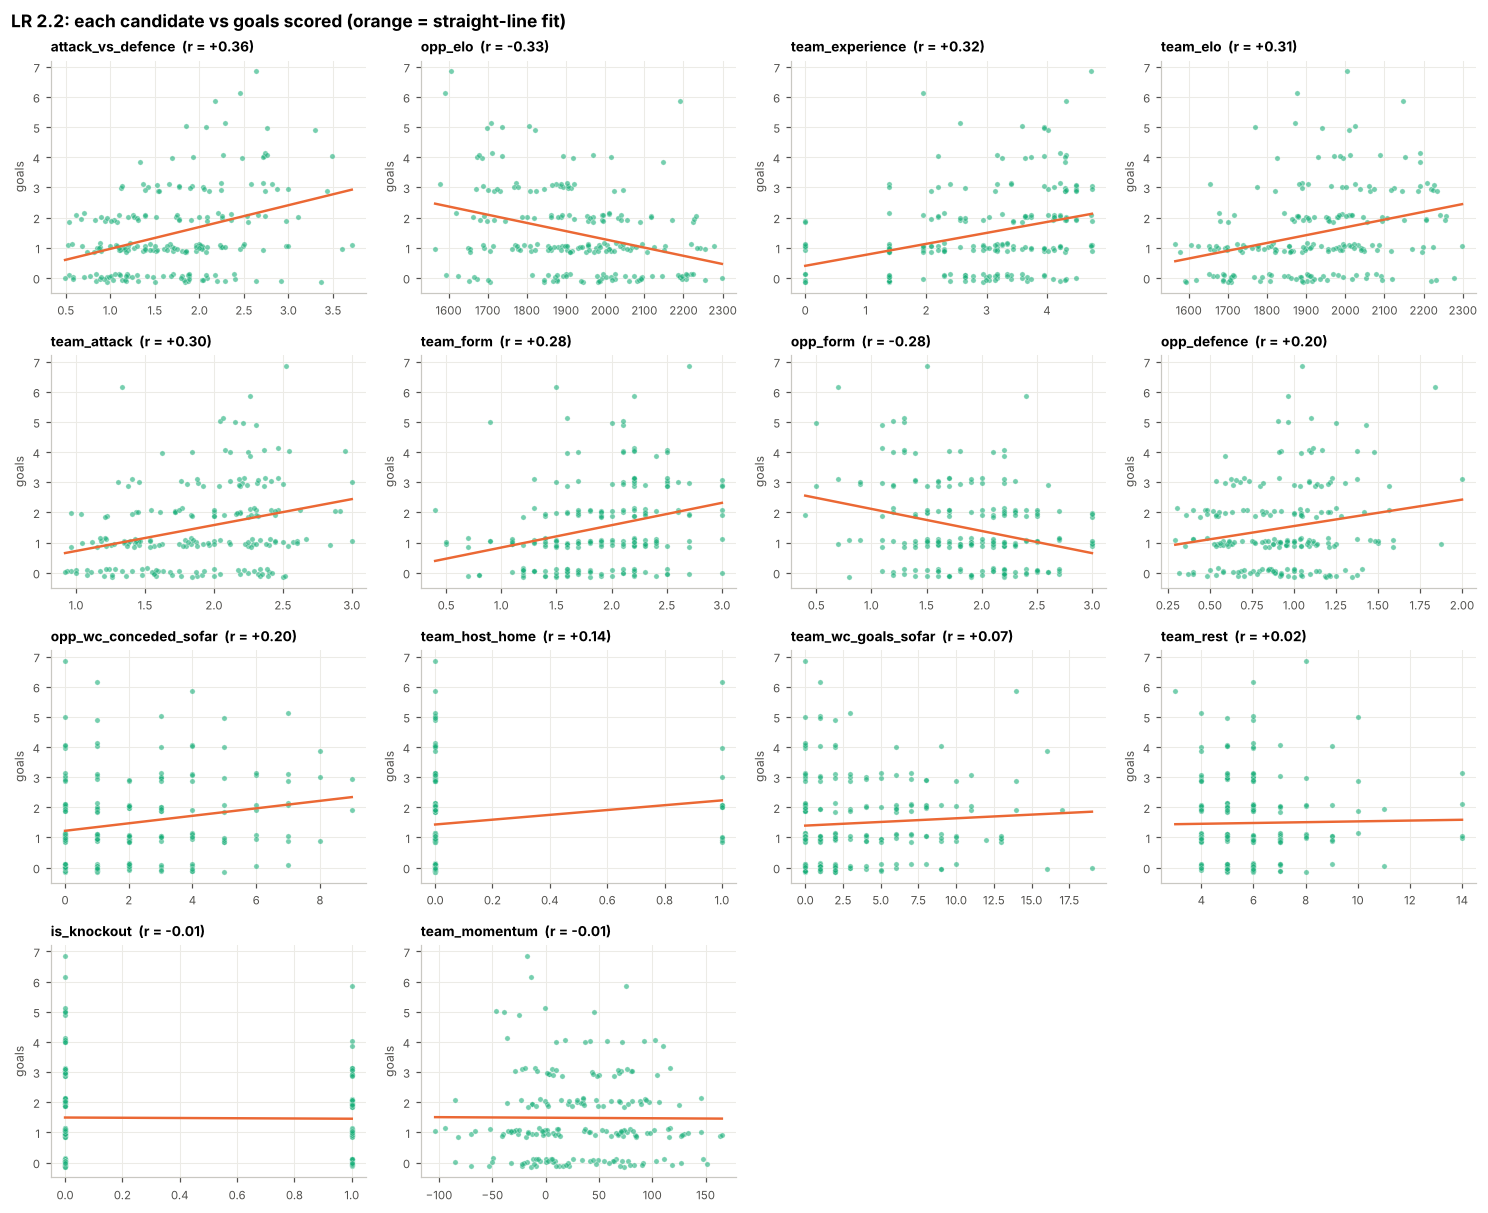

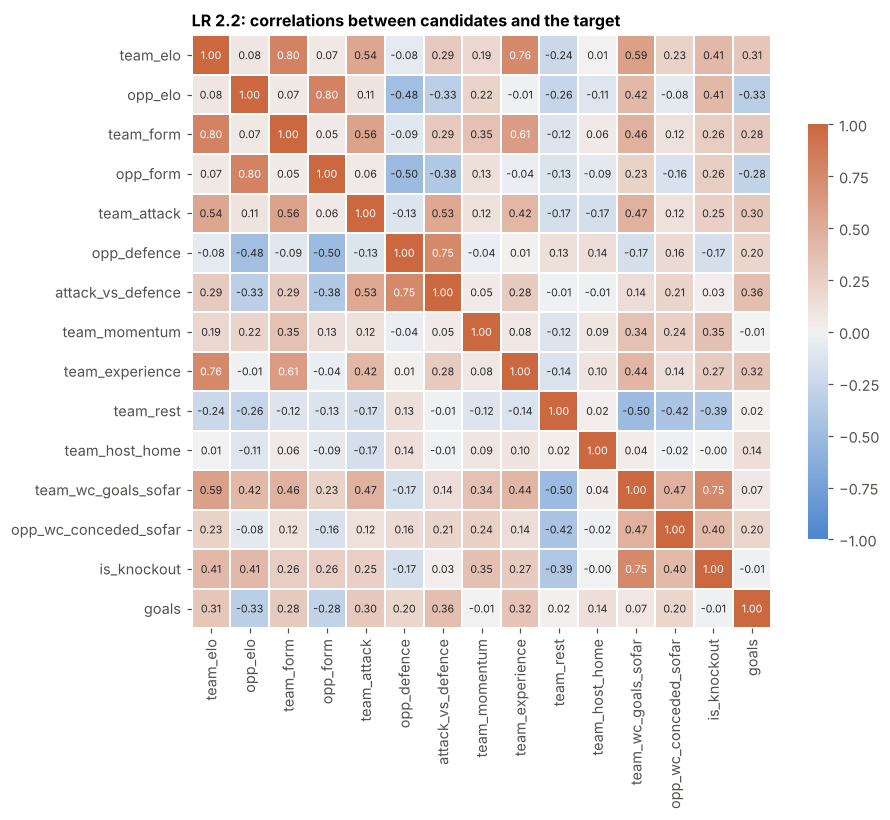

SELECTED (8): ['attack_vs_defence', 'opp_elo', 'team_experience', 'team_elo', 'team_attack', 'team_form', 'opp_form', 'opp_wc_conceded_sofar']
Skipped because of multicollinearity: ['opp_defence']
Not needed (weaker): ['team_host_home', 'team_wc_goals_sofar', 'team_rest', 'is_knockout', 'team_momentum']
Highest VIF among the eight: 4.49


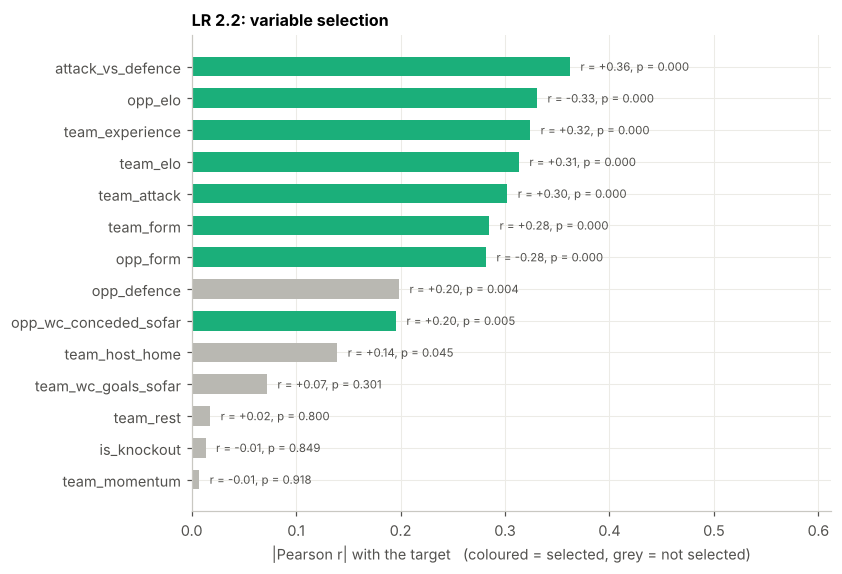

Variables shared with LR 2.1: [] (0 of max 4)
Saved outputs/lr22_dataset.csv (208, 12)


In [18]:
tab22 = eda_table(C22, y22, EXPECT22)
display(tab22.round(4))
print('Expectations confirmed by the sign of r:', int(tab22.sign_as_expected.sum()), 'of', len(tab22))
scatter_grid(C22, y22, tab22, 'LR 2.2: each candidate vs goals scored (orange = straight-line fit)', 'fig09_scatter_22.png', AQUA, 'goals')
heatmap(C22, y22, 'LR 2.2: correlations between candidates and the target', 'fig10_heatmap_22.png')

F22, skipped22 = choose_eight(C22, tab22)
print('SELECTED (8):', F22)
print('Skipped because of multicollinearity:', skipped22)
print('Not needed (weaker):', [c for c in tab22.index if c not in F22 + skipped22])
print('Highest VIF among the eight: %.2f' % max_vif(C22[F22]))
selection_chart(tab22, F22, 'LR 2.2: variable selection', 'fig11_selection_22.png', AQUA)

shared = sorted(set(F21) & set(F22))
print('Variables shared with LR 2.1:', shared, f'({len(shared)} of max 4)')
D22 = pd.concat([groups22, pd.Series(T.team.values, name='team'), pd.Series(O.team.values, name='opponent'), C22[F22], y22], axis=1)
assert len(D22) == 208 and len(F22) == 8 and len(shared) <= 4
D22.to_csv(f'{OUT}/lr22_dataset.csv', index=False)
print('Saved', f'{OUT}/lr22_dataset.csv', D22.shape)

> ### 📊 Results: EDA and selection for LR 2.2
> * **The target:** goals per team range from 0 to 7, with a mean of 1.48 and a median of 1. The distribution is skewed to the right, as is typical of counts.
> * **13 of 14 expectations have the expected sign.** Only `team_momentum` does not, and its r of −0.01 is practically zero.
> * **Our engineered `attack_vs_defence` interaction is the strongest candidate**, with r = +0.36. A good attack facing a leaky defence is the best single signal of goals.
> * **Next strongest:** opponent Elo (r = −0.33), team experience (+0.32), team Elo (+0.31), team attack (+0.30), team form (+0.28) and opponent form (−0.28).
> * **`opp_defence` was skipped**, because it is already part of `attack_vs_defence` and so pushes the VIF too high.
> * **The selected eight have a highest VIF of 4.49.**
> * **The two models share no variables.** LR 2.1 uses match **differences**, while LR 2.2 uses team and opponent **levels** plus an interaction. This is well within the limit of 4.

### 5.3 Fit the multiple linear regression
The two rows of the same match are **not independent**, because they share the same conditions. Standard errors are therefore **clustered by match**. Without that, the p-values would look too small.

                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     3.6943      2.376      1.555      0.120      -0.963       8.352
attack_vs_defence         0.1783      0.149      1.198      0.231      -0.113       0.470
opp_elo                  -0.0028      0.001     -2.781      0.005      -0.005      -0.001
team_experience           0.1547      0.102      1.519      0.129      -0.045       0.354
team_elo                  0.0006      0.001      0.528      0.598      -0.002       0.003
team_attack               0.4583      0.226      2.032      0.042       0.016       0.900
team_form                 0.0902      0.254      0.355      0.723      -0.408       0.588
opp_form                  0.0848      0.290      0.293      0.770      -0.483       0.652
opp_wc_conceded_sofar     0.0595      0.043      1.371      0.170      -0.026       0.145
R² = 0.281

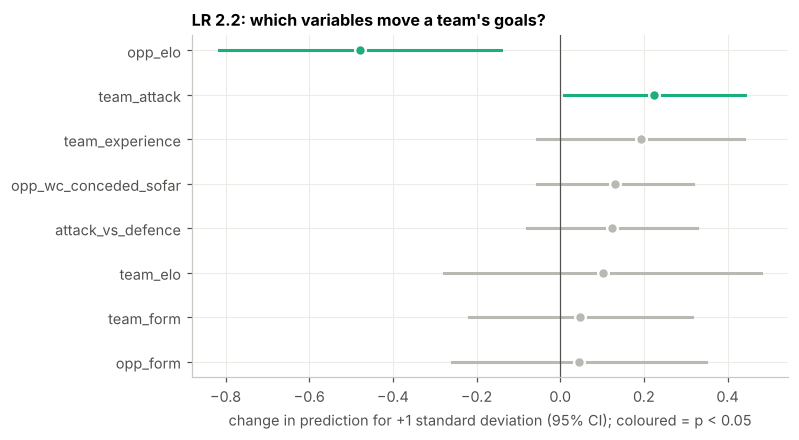

In [19]:
X22, Y22 = D22[F22], D22['goals']
ols22 = sm.OLS(Y22, sm.add_constant(X22)).fit(cov_type='cluster', cov_kwds={'groups': D22.match_id})
print(ols22.summary().tables[1])
print(f'R² = {ols22.rsquared:.3f} | adjusted R² = {ols22.rsquared_adj:.3f} | F-test p = {ols22.f_pvalue:.2e}')
coef_plot(ols22, 'LR 2.2: which variables move a team\'s goals?', 'fig12_coefs_22.png', AQUA)

> ### 📊 Results: OLS for team goals
> * **Overall fit:** R² = 0.281 and adjusted R² = 0.252, with the F-test p ≈ 3×10⁻⁹. The model is clearly better than nothing, but goals per team are much harder to predict than the margin.
> * **`opp_elo` is significant:** b = −0.0028 (p = 0.005). Facing an opponent rated **100 Elo points higher** costs a team about **0.28 goals**.
> * **`team_attack` is significant:** b = 0.46 (p = 0.042). Each extra goal per game in the team's last two years adds almost **half a goal** to its expected score.
> * **`team_experience` is the next closest** (b = 0.15, p = 0.13).
> * **The rest are not significant,** including the team's own Elo and form. **The opponent's strength and the team's own attack matter more for a team's goals than the team's overall rating.** This is an interesting contrast with LR 2.1, where overall strength (Elo) dominated.
> * **The standard errors are clustered by match**, so the p-values allow for the two rows of a match being linked.

### 5.4 Evaluate on unseen matches
The splits keep **both rows of a match together**, so the model never sees one team's row of a match it is tested on. We also add a **Poisson regression**, the standard model for counts like goals, as one more competitor.

HOLD-OUT TEST (52 rows from 26 unseen matches)


,RMSE,MAE,R2
Linear regression,1.232,0.945,0.285
Mean baseline,1.462,1.196,-0.008


REPEATED GROUPED 5-FOLD CV:


,RMSE,MAE,R2
Linear regression,1.233,0.945,0.177


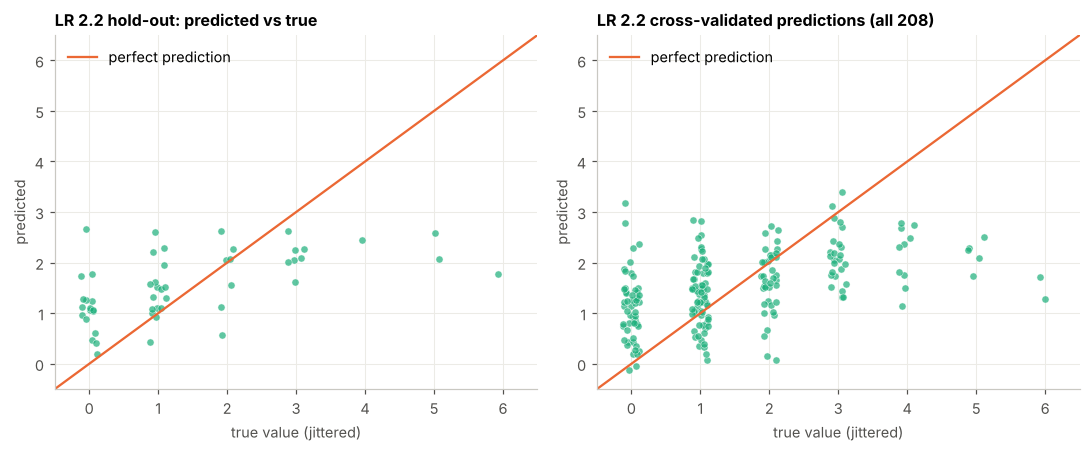

In [20]:
from sklearn.linear_model import PoissonRegressor

tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(X22, Y22, D22.match_id))
p_lin22 = LinearRegression().fit(X22.iloc[tr], Y22.iloc[tr]).predict(X22.iloc[te])
p_base22 = DummyRegressor().fit(X22.iloc[tr], Y22.iloc[tr]).predict(X22.iloc[te])
hold22 = pd.DataFrame({'Linear regression': scores(Y22.iloc[te], p_lin22), 'Mean baseline': scores(Y22.iloc[te], p_base22)}).T
print(f'HOLD-OUT TEST ({len(te)} rows from {D22.match_id.iloc[te].nunique()} unseen matches)'); display(hold22.round(3))

def grouped_repeated_kfold(groups, n_splits=5, n_repeats=10, seed=SEED):
    """Repeated k-fold where both rows of a match always go to the same fold."""
    groups = np.asarray(groups); ids = np.unique(groups); out = []
    for rep in range(n_repeats):
        perm = np.random.RandomState(seed + rep).permutation(ids)
        fold = {g: i % n_splits for i, g in enumerate(perm)}
        f = np.array([fold[g] for g in groups])
        out += [(np.where(f != k)[0], np.where(f == k)[0]) for k in range(n_splits)]
    return out

splits22 = grouped_repeated_kfold(D22.match_id)
cv22, oof22 = cross_validate(LinearRegression(), X22, Y22, splits22)
print('REPEATED GROUPED 5-FOLD CV:'); display(cv22.mean().round(3).to_frame('Linear regression').T)

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
pred_vs_true(ax[0], Y22.iloc[te], p_lin22, 'LR 2.2 hold-out: predicted vs true', AQUA, (-0.5, 6.5))
pred_vs_true(ax[1], Y22, oof22, 'LR 2.2 cross-validated predictions (all 208)', AQUA, (-0.5, 6.5))
plt.tight_layout(); plt.savefig(f'{OUT}/fig13_pred_vs_true_22.png'); plt.show()

### 5.5 Optimising the linear regression step by step
The same six-stage sequence as LR 2.1, scored on the same 50 match-grouped splits. For team goals, the outlier rule removes the **high-scoring rows** (4+ goals) from the training data, which is a real choice: those games are genuine results, not errors.

LR 2.2 step 2 - Ramsey RESET test (H0: the linear form is adequate): F = 7.079, p = 0.008
LR 2.2 step 3 - VIF of each variable (rule: < 5 is acceptable)


,attack_vs_defence,opp_elo,team_experience,team_elo,team_attack,team_form,opp_form,opp_wc_conceded_sofar
VIF,1.86,2.91,2.41,4.49,2.1,3.05,3.05,1.12


LR 2.2 step 1 - rows outside 1.5 x IQR of the response in the full data: 3 (bounds -3.0 to 5.0)


,train R²,test R²,test RMSE,test MAE,p vs baseline
stage,,,,,
0. Baseline OLS,0.2893,0.1774,1.2326,0.9450,NaN
1. + Outlier removal,0.2622,0.2032,1.2175,0.9295,0.5133
2. + Non-linearity check,0.2622,0.2032,1.2175,0.9295,0.5133
3. + Multicollinearity check,0.2622,0.2032,1.2175,0.9295,0.5133
4. + Yeo-Johnson,0.2648,0.2067,1.2150,0.9301,0.4500
5. + Z-standardisation,0.2648,0.2067,1.2150,0.9301,0.4500


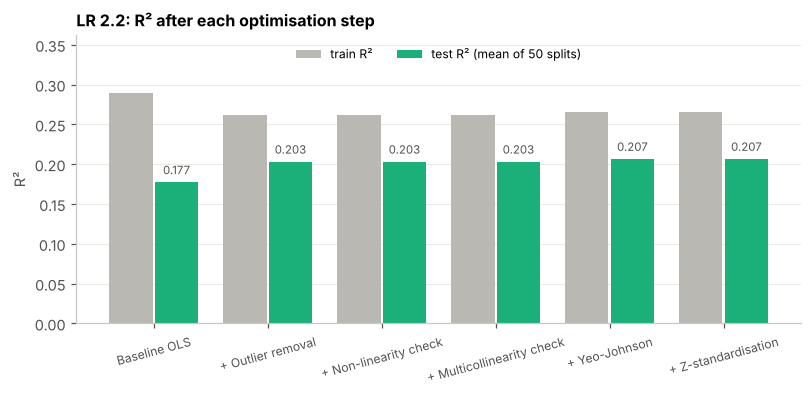

RESET test after outlier removal + Yeo-Johnson: p = 0.007
Training rows removed as outliers in the final fit: 3
Final LR 2.2 model (standardised Yeo-Johnson variables):
goals = 1.4098 + 0.0620·z(attack_vs_defence) − 0.4541·z(opp_elo) + 0.2335·z(team_experience) + 0.0415·z(team_elo) + 0.2535·z(team_attack) + 0.0407·z(team_form) + 0.0501·z(opp_form) + 0.1266·z(opp_wc_conceded_sofar)


In [21]:
checks(X22, Y22, ols22, 'LR 2.2')
opt22 = run_stages(X22, Y22, splits22, 'LR 2.2: R² after each optimisation step', 'fig13a_optimisation_22.png', AQUA)

# does the chosen pipeline remove the curvature? RESET test after outlier removal + Yeo-Johnson
q1, q3 = np.percentile(Y22, [25, 75]); keep = Y22 <= q3 + 1.5 * (q3 - q1)
Xyj = pd.DataFrame(PowerTransformer().fit_transform(X22[keep]), columns=X22.columns, index=X22[keep].index)
r = linear_reset(sm.OLS(Y22[keep], sm.add_constant(Xyj)).fit(), power=2, use_f=True)
print(f'RESET test after outlier removal + Yeo-Johnson: p = {float(r.pvalue):.3f}')

final22 = OptimisedOLS(trim=True, yeo_johnson=True, standardise=True).fit(X22, Y22)
print(f'Training rows removed as outliers in the final fit: {final22.n_removed_}')
print('Final LR 2.2 model (standardised Yeo-Johnson variables):')
print('goals = ' + f'{final22.lr_.intercept_:.4f} ' + ' '.join(f'{"+" if b >= 0 else "−"} {abs(b):.4f}·z({v})' for v, b in zip(X22.columns, final22.lr_.coef_)))

> ### 📊 Results: optimisation of LR 2.2
> * **Step 1, outliers:** 3 rows in the full data lie above the bound of 5 goals, such as Canada's 6 and Germany's 6. Removing high-scoring rows from the training folds raises the test R² from **0.177 to 0.203**. The model is no longer pulled towards rare thrashings.
> * **Step 2, non-linearity:** the RESET test gives **p = 0.008**, so there **is** some curvature. This is expected for a count. Goals cannot go below 0 and tend to rise *multiplicatively* with strength, which is exactly what a Poisson model (log link) assumes. The curvature stays after the later steps (p = 0.007). We cannot add squared terms without breaking the "exactly 8 variables" rule, so the Poisson regression in 5.6 is our test of whether a curved model predicts better.
> * **Step 3, multicollinearity:** all VIFs are below 5 (the highest is 4.49, `team_elo`). Nothing is removed.
> * **Step 4, Yeo-Johnson:** this improves the test R² slightly further, to **0.207** (RMSE 1.215 against the baseline's 1.233).
> * **Step 5, z-standardisation:** this changes only the scale of the coefficients.
> * **The total gain is small and not significant** (p = 0.45), but every step points the same way.
> * **Decision:** for LR 2.2 we keep the **optimised OLS (outlier removal + Yeo-Johnson + z-standardisation)** as the final prediction model. For *interpreting* the effects in goals we still use the original-scale OLS from 5.3, because its coefficients are in real units.

### 5.6 Competing algorithms

Competing algorithms, step 1: hyperparameter tuning (5-fold grid search grouped by match)


,best hyperparameters,tuning RMSE
model,,
k-nearest neighbours,"{'n_neighbors': 30, 'weights': 'distance'}",1.229
Support vector regression,"{'C': 3, 'epsilon': 1.0, 'gamma': 0.03}",1.207
Random forest,"{'max_depth': 5, 'min_samples_leaf': 3}",1.248
Gradient boosting,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est...",1.305


Step 2: all models on the same 50 grouped cross-validation splits


,RMSE,RMSE_se,MAE,R2
Optimised OLS (final),1.215,0.026,0.930,0.207
Support vector regression,1.219,0.027,0.928,0.196
k-nearest neighbours,1.219,0.027,0.936,0.202
Ridge,1.221,0.025,0.938,0.196
Lasso,1.226,0.025,0.940,0.188
Linear regression,1.233,0.025,0.945,0.177
Poisson regression,1.234,0.030,0.933,0.170
Random forest,1.268,0.025,0.966,0.123
Gradient boosting,1.281,0.025,0.972,0.112
Mean baseline,1.387,0.025,1.117,-0.035


Is each model different from linear regression? (corrected t-test on RMSE)


,RMSE − linear RMSE,t,p_value
model,,,
Optimised OLS (final),-0.018,-0.762,0.450
Support vector regression,-0.014,-0.621,0.537
k-nearest neighbours,-0.013,-0.457,0.650
Ridge,-0.012,-0.844,0.403
Lasso,-0.007,-0.783,0.437
Poisson regression,0.001,0.024,0.981
Random forest,0.035,1.029,0.309
Gradient boosting,0.048,1.717,0.092
Mean baseline,0.154,3.668,0.001


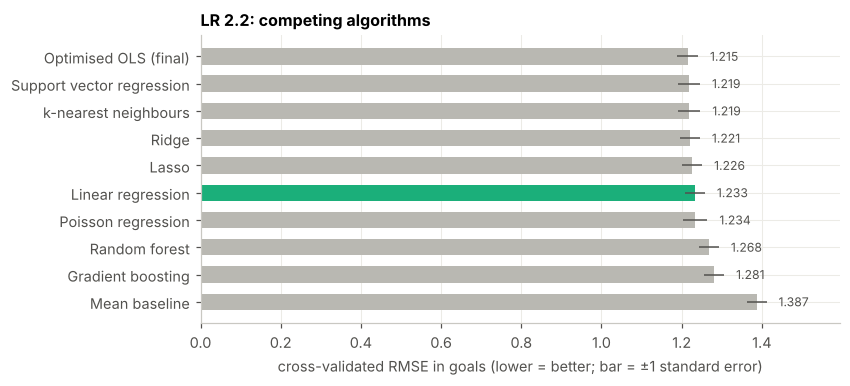

In [22]:
print('Competing algorithms, step 1: hyperparameter tuning (5-fold grid search grouped by match)')
tuned22 = tune(X22, Y22, groups=D22.match_id)
print('Step 2: all models on the same 50 grouped cross-validation splits')
poisson = {'Poisson regression': make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-3, max_iter=1000)),
           'Optimised OLS (final)': OptimisedOLS(trim=True, yeo_johnson=True, standardise=True)}
comp22 = compare_models(competitors(tuned22, poisson), X22, Y22, splits22, 'LR 2.2: competing algorithms', 'fig14_competing_22.png', AQUA)

> ### 📊 Results and recommendation: LR 2.2
> * **Hold-out test on 52 rows from 26 unseen matches:** R² = 0.285, RMSE = 1.23, against the baseline's 1.46.
> * **Grouped CV over 50 test sets (baseline OLS):** R² = 0.177, RMSE = 1.23 and MAE = 0.95, against the baseline's RMSE of 1.39.
> * **The plots show predictions mostly between 0.5 and 2.5 goals.** The model separates low- and high-scoring teams on average but cannot foresee 4–7-goal games.
> * **Tuning:** the grid search again chose cautious settings, such as k-NN with **30 neighbours** and gradient boosting with **depth-2 trees**.
> * **Competing algorithms (CV RMSE):**
>
>   | Model | RMSE | R² |
>   |---|---|---|
>   | **Optimised OLS (final)** | **1.215** | **0.207** |
>   | Support vector regression | 1.219 | 0.196 |
>   | k-nearest neighbours | 1.219 | 0.202 |
>   | Ridge | 1.221 | 0.196 |
>   | Lasso | 1.226 | 0.188 |
>   | Linear regression (baseline OLS) | 1.233 | 0.177 |
>   | Poisson regression | 1.234 | 0.170 |
>   | Random forest | 1.268 | 0.123 |
>   | Gradient boosting | 1.281 | 0.112 |
>   | Mean baseline | 1.387 | −0.035 |
>
>   **No model is significantly better than linear regression** (all p > 0.09). The baseline is significantly worse (p = 0.001).
> * **Our optimised OLS has the lowest error of all ten models**, ahead of the tuned SVR and k-NN. Its error is **12% below** the mean baseline.
> * **The Poisson regression, built for counts, gives no gain** even though the RESET test found some curvature. The curvature is real but too weak to matter for prediction at this sample size.
> * **The tree ensembles are the weakest real models.** With 208 rows they overfit.
> * **Recommendation:** use the **optimised multiple linear regression** (outlier removal, Yeo-Johnson, z-standardisation) as the LR 2.2 model.
>   * It is the most accurate model tested.
>   * It stays a transparent linear equation, with standardised coefficients that rank the variables directly: opponent Elo first, then team attack and team experience.
>   * Tree ensembles and the Poisson model are not recommended at this sample size.

## 6 · Do the linear regression assumptions hold?
* **Residuals vs fitted:** should be a cloud with no pattern around 0.
* **Normal Q-Q plot:** the points should lie near the line if the errors are roughly normal.
* **Shapiro–Wilk:** tests normality of the errors.
* **Breusch–Pagan:** tests whether the spread of the errors is equal.

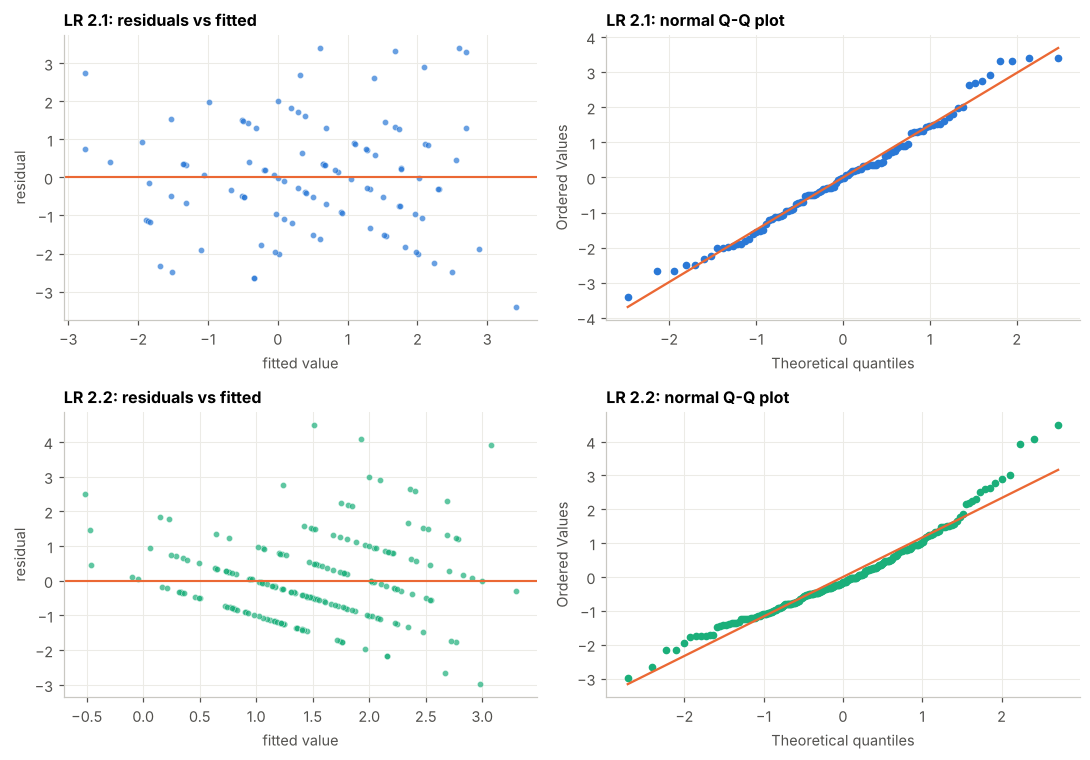

,Shapiro–Wilk p,Breusch–Pagan p
model,,
LR 2.1,0.3193,0.1611
LR 2.2,0.0000,0.0324


In [23]:
fig, ax = plt.subplots(2, 2, figsize=(10, 7)); rows = []
for i, (name, res, col) in enumerate([('LR 2.1', ols21, BLUE), ('LR 2.2', ols22, AQUA)]):
    ax[i, 0].scatter(res.fittedvalues, res.resid, s=16, color=col, alpha=0.7, edgecolor='white', linewidth=0.3)
    ax[i, 0].axhline(0, color=ORANGE, lw=1.4); ax[i, 0].set(title=f'{name}: residuals vs fitted', xlabel='fitted value', ylabel='residual')
    stats.probplot(res.resid, plot=ax[i, 1]); ax[i, 1].get_lines()[0].set(color=col, markersize=4); ax[i, 1].get_lines()[1].set(color=ORANGE)
    ax[i, 1].set_title(f'{name}: normal Q-Q plot')
    rows.append({'model': name, 'Shapiro–Wilk p': stats.shapiro(res.resid).pvalue,
                 'Breusch–Pagan p': het_breuschpagan(res.resid, res.model.exog)[1]})
plt.tight_layout(); plt.savefig(f'{OUT}/fig15_residuals.png'); plt.show()
display(pd.DataFrame(rows).set_index('model').round(4))

> ### 📊 Results: assumption checks
> * **LR 2.1:** the residuals are **normal** (Shapiro–Wilk p = 0.32), and the Q-Q plot follows the line closely. The spread is **even** (Breusch–Pagan p = 0.16). The residuals-vs-fitted plot shows no curve. All OLS assumptions are satisfied; the HC3 robust standard errors are a precaution.
> * **LR 2.2:** the residuals are **not normal** (Shapiro–Wilk p < 0.001), and the spread is uneven (Breusch–Pagan p = 0.032). Both are expected because goals are whole numbers that cannot go below 0, and the Q-Q plot lifts at the top end from the rare high-scoring games. The coefficient estimates are still unbiased, the clustered standard errors protect the tests, and the Poisson model, which is built for counts, did not predict better. **The violation is therefore noted as a limitation rather than a reason to reject the model.**

## 7 · Summary of both tasks
One table and one chart that sum up the whole notebook: how much each model improves on guessing the average, and how the best competing algorithm compares.

,LR 2.1 (goal difference),LR 2.2 (team goals)
rows,104,208
explanatory variables,8,8
final model,baseline OLS,optimised OLS
in-sample R² (OLS),0.468,0.281
adjusted R² (OLS),0.423,0.252
final model CV R²,0.292,0.207
final model CV RMSE,1.617,1.215
mean-baseline RMSE,2.019,1.387
best competing model,Support vector regression,Support vector regression
best competing RMSE,1.57,1.219


Variables LR 2.1: ['elo_win_exp', 'experience_diff', 'form_diff', 'defence_diff', 'attack_diff', 'conf_diff', 'wc_gd_sofar_diff', 'momentum_diff']
Variables LR 2.2: ['attack_vs_defence', 'opp_elo', 'team_experience', 'team_elo', 'team_attack', 'team_form', 'opp_form', 'opp_wc_conceded_sofar']
Shared: []


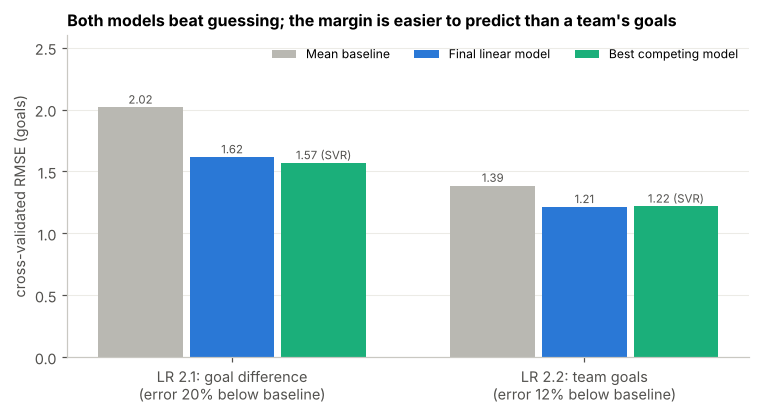

In [24]:
OURS = ['Linear regression', 'Optimised OLS (final)', 'Mean baseline']
best21 = comp21.drop(index=[m for m in OURS if m in comp21.index]).RMSE.idxmin()
best22 = comp22.drop(index=[m for m in OURS if m in comp22.index]).RMSE.idxmin()
final_cv = {'LR 2.1': (cv21.R2.mean(), cv21.RMSE.mean()),
            'LR 2.2': (comp22.loc['Optimised OLS (final)', 'R2'], comp22.loc['Optimised OLS (final)', 'RMSE'])}
summary = pd.DataFrame({
    'LR 2.1 (goal difference)': [104, 8, 'baseline OLS', round(ols21.rsquared, 3), round(ols21.rsquared_adj, 3),
                                 round(final_cv['LR 2.1'][0], 3), round(final_cv['LR 2.1'][1], 3),
                                 round(comp21.loc['Mean baseline', 'RMSE'], 3), best21, round(comp21.loc[best21, 'RMSE'], 3)],
    'LR 2.2 (team goals)':      [208, 8, 'optimised OLS', round(ols22.rsquared, 3), round(ols22.rsquared_adj, 3),
                                 round(final_cv['LR 2.2'][0], 3), round(final_cv['LR 2.2'][1], 3),
                                 round(comp22.loc['Mean baseline', 'RMSE'], 3), best22, round(comp22.loc[best22, 'RMSE'], 3)]},
    index=['rows', 'explanatory variables', 'final model', 'in-sample R² (OLS)', 'adjusted R² (OLS)', 'final model CV R²',
           'final model CV RMSE', 'mean-baseline RMSE', 'best competing model', 'best competing RMSE'])
display(summary)
summary.to_csv(f'{OUT}/summary.csv')
print('Variables LR 2.1:', F21)
print('Variables LR 2.2:', F22)
print('Shared:', shared)

short = {'Support vector regression': 'SVR', 'k-nearest neighbours': 'k-NN', 'Random forest': 'RF', 'Gradient boosting': 'GB'}
vals = {'Mean baseline': [comp21.loc['Mean baseline', 'RMSE'], comp22.loc['Mean baseline', 'RMSE']],
        'Final linear model': [final_cv['LR 2.1'][1], final_cv['LR 2.2'][1]],
        'Best competing model': [comp21.loc[best21, 'RMSE'], comp22.loc[best22, 'RMSE']]}
best_names = [short.get(n, n) for n in (best21, best22)]
gains = [1 - vals['Final linear model'][j] / vals['Mean baseline'][j] for j in range(2)]
labels = [f'LR 2.1: goal difference\n(error {gains[0]:.0%} below baseline)', f'LR 2.2: team goals\n(error {gains[1]:.0%} below baseline)']
fig, ax = plt.subplots(figsize=(8, 3.8)); w = 0.26; x = np.arange(2)
for k, (name, col) in enumerate(zip(vals, [GREY, BLUE, AQUA])):
    bars = ax.bar(x + (k - 1) * w, vals[name], width=w - 0.02, color=col, label=name)
    for j, b in enumerate(bars):
        txt = f'{b.get_height():.2f}' + (f' ({best_names[j]})' if k == 2 else '')
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.03, txt, ha='center', fontsize=7.5, color=INK)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0, 2.6)
ax.set(ylabel='cross-validated RMSE (goals)', title='Both models beat guessing; the margin is easier to predict than a team\'s goals')
ax.legend(ncol=3, loc='upper right', fontsize=8); ax.grid(axis='x', visible=False)
plt.savefig(f'{OUT}/fig16_summary.png'); plt.show()

## 8 · Conclusion
**What we did.**
* **Data:** the 104 World Cup 2026 matches from FBref, cross-checked against an independent file of about 49,900 internationals since 1872. The two agree on every score.
* **Variables:** we built our own pre-match variables from the match history (Elo rating, form, attack and defence records, World Cup experience, rest, host advantage, tournament form) and proved there is no leakage.
* **Selection:** we chose eight variables per model with a written |r| plus VIF rule.
* **Models and evaluation:** we fitted two multiple linear regressions, applied the five optimisation steps (outliers, non-linearity, multicollinearity, Yeo-Johnson, z-standardisation), and evaluated them on unseen matches against eight to nine competing algorithms, each tuned with a grid search.

**What we found.**
* **LR 2.1 (goal difference):** on unseen matches the model explains about **29%** of the variation (CV R² = 0.29), and its typical error is **1.62 goals**, against 2.02 for guessing. The key driver is **Elo win expectancy**: +10 percentage points gives about +0.39 goals.
* **LR 2.2 (team goals):** the optimised model reaches CV R² = 0.21 and RMSE 1.22, against 1.39 for guessing. A team's goals depend mainly on **the opponent's strength** (100 Elo points stronger gives about −0.28 goals) and **the team's own attacking record** (about +0.46 goals per extra goal per game).
* **Optimisation:** for LR 2.1 none of the steps helped, so the baseline OLS is final. For LR 2.2, removing training outliers and applying Yeo-Johnson raised the CV R² from 0.177 to 0.207. The gain was small and not significant, but consistent.
* **How the two models relate:** the margin of a match (2.1) is easier to predict than one team's goals (2.2). The overall strength gap decides who wins by how much, but the exact number of goals scored is noisier.
* **Competing algorithms:** after tuning, no competitor was significantly better than linear regression in either task (all corrected t-test p > 0.09). In LR 2.1 the best model, SVR, was only 0.05 goals better; in LR 2.2 our optimised OLS was the most accurate of all ten models. **Multiple linear regression is recommended** for both tasks: the baseline OLS for LR 2.1 and the optimised OLS for LR 2.2.
* **The story in one line:** the strength gap between two teams, as captured by our Elo rating, is the single most useful thing to know before a World Cup match, and a team's goals depend more on who it faces than on how good it is itself.

**Limitations.**
* Only 104 matches, so the results vary between splits.
* Football scores contain a lot of luck.
* Extra-time goals are included for 9 knock-out matches, which gives those teams slightly more playing time.
* Our Elo is our own estimate, not an official rating.
* LR 2.2's residuals are not normal, and the RESET test found mild curvature, typical of a count response.

**Future work.**
* Add squad market values, player injuries and suspensions, and travel distance.
* Train on earlier World Cups (2014–2022) to get more data.